# Proyecto 2: Monitoreo de Eventos de Infraestructura, Confiabilidad & Salud de Sistemas

**Rol:** Principal Data Engineer / Data Lead — Mantenimiento Predictivo (PdM), IoT e Ingeniería de Confiabilidad

**Objetivo:** Construir un pipeline ETL modular, vectorizado (Pandas/NumPy) y auditable sobre el dataset Azure PdM (Kaggle), que:
1. Preserve la soberanía de los datos de sensores, manteniendo los registros intactos y etiquetando picos físicos mediante flags de anomalía (sin eliminación ni imputación de outliers).
2. Distinga explícitamente entre "nulos estructurales" (0% en este dataset) y "nulos lógicos" (ausencia de registro de falla = operación 100% saludable).
3. Agregue y resamplee la telemetría continua a frecuencia fija (1 hora) asegurando la continuidad de la serie temporal mediante interpolación basada en tiempo (`method='time'`).
4. Derive variables de secuencia (Rolling Averages y Lags) y compute KPIs de confiabilidad industrial (MTBF, MTTR, % Uptime) agrupados por máquina y modelo de equipo para alimentar el Modelo Dimensional Kimball.

---

### Reglas de negocio obligatorias (dominio industrial)

| Regla | Descripción |
|:---|:---|
| **Soberanía del dato** | Los sensores (`volt`, `rotate`, `pressure`, `vibration`) no tienen nulos estructurales. Los outliers **no se eliminan ni se imputan**: son señales físicas de degradación que se etiquetan con flags lógicas (`is_anomaly`). |
| **Nulos lógicos** | La ausencia de un registro en `PdM_failures` para una máquina **no es un dato faltante**: representa operación saludable continua (clase negativa de control). No se imputa. |
| **Eventos simultáneos** | Múltiples registros en el mismo `(timestamp, machineID)` dentro de `PdM_errors` / `PdM_maint` **no son duplicados**: son eventos legítimos simultáneos (ej. reemplazo de múltiples componentes en el mismo turno). |
| **Series temporales** | Se realiza alineación y resampleo de telemetría a frecuencia fija de **1 hora** (`resample('1h')`). Se aplica interpolación lineal temporal (`method='time'`) únicamente para corregir discontinuidades o vacíos en el eje de tiempo. |

In [3]:
# =========================================================================
# LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# =========================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_theme(style="whitegrid")

# Directorios de entrada / salida
DATA_DIR = "./"
OUTPUT_DIR = "./data_processed/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Parámetros de negocio configurables
RESAMPLE_FREQ = "1h"          # Frecuencia objetivo de alineación de telemetría
IQR_MULTIPLIER = 1.5          # Multiplicador estándar de Tukey para IQR
ZSCORE_THRESHOLD = 3.0        # Umbral Z-Score para detección alternativa
ROLLING_WINDOWS_H = [3, 6, 24]  # Ventanas de promedio móvil (horas)
LAG_HOURS = [1, 3]              # Horizontes de rezago (lag)

# Asunciones de SLA de mantenimiento / downtime (horas)
MAINT_DOWNTIME_HOURS = 6.0     # Downtime promedio por mantenimiento planificado
FAILURE_DOWNTIME_HOURS = 12.0  # Downtime promedio por falla no planificada

print("Configuración global cargada correctamente.")

Configuración global cargada correctamente.


## BLOQUE 1: Ingesta, Parseo y Tipado Estricto de Datos

**Lógica de Negocio y Arquitectura de Ingesta:**
El conjunto de datos consta de 5 archivos CSV con estructura relacional: 
1. `PdM_telemetry.csv` (Telemetría continua de sensores)
2. `PdM_errors.csv` (Registros de errores no catastróficos)
3. `PdM_failures.csv` (Eventos de falla de componentes)
4. `PdM_maint.csv` (Historial de mantenimientos preventivos y correctivos)
5. `PdM_machines.csv` (Dimensión de metadatos del equipo)

Es crítico forzar un *Schema Enforcement* estricto desde la lectura:
* **Parseo Temporal:** Conversión explícita del campo `datetime` a formato `datetime64[ns]` para todas las tablas.
* **Ordenamiento Secuencial:** Ordenamiento físico de los registros por `[machineID, datetime]`. Todo el pipeline posterior (alineación, resampleo, rolling windows, lags y KPIs de confiabilidad) asume la continuidad física del tiempo por máquina; cualquier sesgo o desorden en esta etapa corrompería silenciosamente los cálculos posteriores.
* **Preservación de Tipos de Datos:** Asegurar que `machineID` se mantenga como `int64` (para joins relacionales) y los valores de telemetría (`volt`, `rotate`, `pressure`, `vibration`) conserven precisión `float64`.

In [4]:
# =========================================================================
# BLOQUE 1: INGESTA, PARSEO Y TIPADO ESTRICTO
# =========================================================================
df_telemetry = pd.read_csv(os.path.join(DATA_DIR, "PdM_telemetry.csv"))
df_errors    = pd.read_csv(os.path.join(DATA_DIR, "PdM_errors.csv"))
df_maint     = pd.read_csv(os.path.join(DATA_DIR, "PdM_maint.csv"))
df_failures  = pd.read_csv(os.path.join(DATA_DIR, "PdM_failures.csv"))
df_machines  = pd.read_csv(os.path.join(DATA_DIR, "PdM_machines.csv"))

raw_tables = {
    "PdM_telemetry": df_telemetry,
    "PdM_errors": df_errors,
    "PdM_maint": df_maint,
    "PdM_failures": df_failures,
    "PdM_machines": df_machines,
}

# Tipado estricto de fechas y ordenamiento cronológico por máquina
for name in ["PdM_telemetry", "PdM_errors", "PdM_maint", "PdM_failures"]:
    df = raw_tables[name]
    df["datetime"] = pd.to_datetime(df["datetime"])
    df.sort_values(["machineID", "datetime"], inplace=True)
    df.reset_index(drop=True, inplace=True)

df_telemetry, df_errors, df_maint, df_failures = (
    raw_tables["PdM_telemetry"], raw_tables["PdM_errors"],
    raw_tables["PdM_maint"], raw_tables["PdM_failures"],
)
df_machines.sort_values("machineID", inplace=True)
df_machines.reset_index(drop=True, inplace=True)

# Data Profiling inicial
def profile_table(name, df):
    mem_mb = df.memory_usage(deep=True).sum() / 1_048_576
    n_nulls = df.isnull().sum().sum()
    n_machines = df["machineID"].nunique() if "machineID" in df.columns else np.nan
    print(f"--- {name} ---")
    print(f"  Shape         : {df.shape}")
    print(f"  Memoria (MB)  : {mem_mb:.2f}")
    print(f"  Nulos totales : {n_nulls} (esperado: 0)")
    print(f"  Máquinas únicas: {n_machines}\n")

for name, df in raw_tables.items():
    profile_table(name, df)

--- PdM_telemetry ---
  Shape         : (876100, 6)
  Memoria (MB)  : 40.10
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100

--- PdM_errors ---
  Shape         : (3919, 3)
  Memoria (MB)  : 0.30
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100

--- PdM_maint ---
  Shape         : (3286, 3)
  Memoria (MB)  : 0.24
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100

--- PdM_failures ---
  Shape         : (761, 3)
  Memoria (MB)  : 0.06
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 98

--- PdM_machines ---
  Shape         : (100, 3)
  Memoria (MB)  : 0.01
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100



## BLOQUE 2: Alineación y Resampleo de Series Temporales (Telemetría Continua)

**Lógica de Negocio y Criterio Técnico:**
La telemetría de sensores requiere una grilla temporal continua y uniforme por cada máquina (`machineID`) a frecuencia fija de **1 hora** (`resample('1h')`), consistente con la resolución nativa del dataset. 

* **Reconstrucción del Índice Temporal:** Se genera la secuencia horaria completa por máquina para garantizar la alineación del eje $t$.
* **Imputación de Vacíos Temporales (Gaps):** Si existen vacíos de lectura por discontinuidades en la transmisión de datos del sensor, se aplica **interpolación lineal adaptada al tiempo** (`method='time'`). Este enfoque conserva la inercia física y la continuidad dinámica de las señales (`volt`, `rotate`, `pressure`, `vibration`), evitando distorsiones como las causadas por *forward-fill* o la media global.
* **Aislamiento de Eventos Discretos:** Las tablas de eventos (`PdM_errors`, `PdM_maint`, `PdM_failures`) representan ocurrencias discretas no continuas. **Quedan estrictamente excluidas de cualquier proceso de resampleo e interpolación** para evitar la generación de eventos ficticios.

In [5]:
# =========================================================================
# BLOQUE 2: ALINEACIÓN Y RESAMPLEO DE SERIES TEMPORALES
# =========================================================================
sensor_cols = ["volt", "rotate", "pressure", "vibration"]

# Resampleo robusto por máquina utilizando Pivot / Resample / Stack
df_pivoted = df_telemetry.pivot(index="datetime", columns="machineID", values=sensor_cols)
df_resampled = df_pivoted.resample(RESAMPLE_FREQ).mean()

# Interpolación lineal temporal
df_resampled = df_resampled.interpolate(method="time", limit_direction="both")

# Reestructurar a formato largo (long format) - Compatible con versiones previas de Pandas
telemetry_resampled = df_resampled.stack(level="machineID").reset_index()
telemetry_resampled.sort_values(["machineID", "datetime"], inplace=True)
telemetry_resampled.reset_index(drop=True, inplace=True)

df_telemetry_clean = telemetry_resampled.copy()
print("Shape telemetría alineada e interpolada:", df_telemetry_clean.shape)
print("Nulos restantes:", df_telemetry_clean[sensor_cols].isnull().sum().to_dict())

Shape telemetría alineada e interpolada: (876100, 6)
Nulos restantes: {'volt': 0, 'rotate': 0, 'pressure': 0, 'vibration': 0}


## BLOQUE 3: Detección Estadística de Anomalías (Sin Eliminación de Datos)

**Lógica de Negocio y Fundamentos Estadísticos:**
En mantenimiento predictivo e ingeniería de confiabilidad, los valores extremos (*outliers*) de los sensores **no son errores de captura ni datos corruptos**: constituyen la evidencia física de la degradación progresiva previa a una falla catastrófica del equipo. 

Por esta razón, **se preservan al 100% los valores originales** de la telemetría y se generan variables lógicas tipo bandera (*anomaly flags*).

* **Límites Operativos Dinámicos por Máquina:**
  Dado que cada equipo posee un comportamiento operativo propio (debido a diferencias de modelo o antigüedad), los umbrales se calculan **por máquina ($m$)** mediante el Rango Intercuartílico ($IQR$):

  $$IQR_m = Q_3(S_{m}) - Q_1(S_{m})$$

  $$\text{Límite Inferior}_m = Q_1(S_m) - 1.5 \times IQR_m, \quad \text{Límite Superior}_m = Q_3(S_m) + 1.5 \times IQR_m$$

* **Generación de Flags de Anomalía:**
  1. **Flags Individuales:** Se evalúan las desviaciones atípicas para cada una de las 4 variables físicas: `is_volt_anomaly`, `is_rotate_anomaly`, `is_pressure_anomaly` e `is_vibration_anomaly`.
  2. **Flag Consolidada:** Se deriva `is_sensorial_anomaly` (Booleana / 0 o 1) mediante una condición OR lógica, indicando si al menos uno de los sensores excedió sus límites operativos dinámicos en esa marca de tiempo.

In [6]:
# =========================================================================
# BLOQUE 3: DETECCIÓN ESTADÍSTICA DE ANOMALÍAS (IQR + Z-SCORE)
# =========================================================================
# 3.1 Método 1: IQR por Máquina
def compute_iqr_bounds(df, cols, k=IQR_MULTIPLIER):
    q1 = df.groupby("machineID")[cols].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby("machineID")[cols].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lower_iqr, upper_iqr = compute_iqr_bounds(df_telemetry_clean, sensor_cols)

for col in sensor_cols:
    df_telemetry_clean[f"is_{col}_anomaly_iqr"] = (
        (df_telemetry_clean[col] < lower_iqr[col]) | (df_telemetry_clean[col] > upper_iqr[col])
    ).astype(int)

# 3.2 Método 2: Z-Score por Máquina (COMPLEMENTO REQUERIDO)
for col in sensor_cols:
    mean = df_telemetry_clean.groupby("machineID")[col].transform("mean")
    std = df_telemetry_clean.groupby("machineID")[col].transform("std")
    z_score = (df_telemetry_clean[col] - mean) / std
    df_telemetry_clean[f"zscore_{col}"] = z_score
    df_telemetry_clean[f"is_{col}_anomaly_z"] = (z_score.abs() > ZSCORE_THRESHOLD).astype(int)

# Flags consolidadas
iqr_flags = [f"is_{c}_anomaly_iqr" for c in sensor_cols]
z_flags = [f"is_{c}_anomaly_z" for c in sensor_cols]

df_telemetry_clean["is_sensorial_anomaly"] = (df_telemetry_clean[iqr_flags].sum(axis=1) > 0).astype(int)
df_telemetry_clean["is_sensorial_anomaly_z"] = (df_telemetry_clean[z_flags].sum(axis=1) > 0).astype(int)

print(f"Tasa anomalía sensorial (IQR): {df_telemetry_clean['is_sensorial_anomaly'].mean()*100:.2f}%")
print(f"Tasa anomalía sensorial (Z-Score): {df_telemetry_clean['is_sensorial_anomaly_z'].mean()*100:.2f}%")

Tasa anomalía sensorial (IQR): 4.76%
Tasa anomalía sensorial (Z-Score): 2.02%


## BLOQUE 4: Feature Engineering de Secuencia (Rolling Windows & Lags)

**Lógica de Negocio y Criterios de Secuencia Temporal:**
El valor instantáneo de un sensor solo representa una captura puntual; la **degradación física** de un componente mecánico se manifiesta a través de patrones de tendencia y aceleración acumulada a lo largo del tiempo. 

Para capturar la historia reciente del comportamiento operativo, se construyen variables de secuencia agrupando estrictamente **por máquina (`machineID`)**:

* **Promedios Móviles (Rolling Averages - 3h, 6h, 24h):**
  Suavizan el ruido de alta frecuencia y calculan el nivel de fatiga acumulada en las variables físicas ($S_m$):

  $$\bar{S}_{m, t}^{(w)} = \frac{1}{w} \sum_{i=0}^{w-1} S_{m, t-i} \quad \text{para } w \in \{3, 6, 24\} \text{ horas}$$

* **Variables de Retardo (Lags Temporales - 1h, 3h, 6h):**
  Capturan la velocidad instantánea de cambio y la aceleración de la degradación antes de un evento de falla:

  $$\text{Lag}_{k}(S_{m, t}) = S_{m, t-k} \quad \text{para } k \in \{1, 3, 6\} \text{ horas}$$

* **Aislamiento por Máquina:** 
  Todas las transformaciones de ventana se ejecutan utilizando `.groupby('machineID')` para evitar la contaminación cruzada de series temporales (*data leakage*) entre distintos equipos.

In [7]:
# =========================================================================
# BLOQUE 4: FEATURE ENGINEERING DE SECUENCIA (WINDOWS & LAGS)
# =========================================================================
df_telemetry_clean.sort_values(["machineID", "datetime"], inplace=True)

# Rolling Averages (3h, 6h, 24h)
for window in ROLLING_WINDOWS_H:
    for col in sensor_cols:
        df_telemetry_clean[f"{col}_roll_{window}h"] = (
            df_telemetry_clean.groupby("machineID")[col]
            .transform(lambda s: s.rolling(window=window, min_periods=1).mean())
        )

# Lags (1h, 3h)
for lag in LAG_HOURS:
    for col in sensor_cols:
        df_telemetry_clean[f"{col}_lag_{lag}h"] = (
            df_telemetry_clean.groupby("machineID")[col].shift(lag)
        )

print("Features de secuencia generadas correctamente.")

Features de secuencia generadas correctamente.


## BLOQUE 5: Cálculo de KPIs de Ingeniería de Confiabilidad Industrial

**Lógica de Negocio y Formulación Matemática:**
Se derivan las métricas estándar de resiliencia y disponibilidad para cada máquina ($m$), evaluadas sobre la ventana temporal total observada ($T_{\text{observado}}$):

* **Mean Time Between Failures (MTBF - Tiempo Medio Entre Fallas):**
  Mide el tiempo promedio de operación continua entre eventos de falla consecutivos registrados en `PdM_failures`.
  
  $$\text{MTBF}_m = \frac{T_{\text{operativo}_m}}{N_{f, m}}$$

  > *Nota de Negocio:* Si una máquina no registra fallas ($N_{f, m} = 0$), representa el grupo de control (100% saludable). Su $\text{MTBF}_m$ se define como el total del periodo de observación ($T_{\text{observado}}$) sin imputar valores artificiales.

* **Mean Time to Repair (MTTR - Tiempo Medio de Reparación):**
  Dado que la telemetría no incluye un timestamp explícito de fin de reparación, se calcula integrando las constantes de *downtime* según el SLA operativo documentado:
  
  $$\text{MTTR}_m = \frac{\sum \text{Downtime Planificado } (D_{\text{maint}}) + \sum \text{Downtime No Planificado } (D_{\text{falla}})}{N_{\text{intervenciones}, m}}$$
  
  * *Mantenimiento Preventivo:* `MAINT_DOWNTIME_HOURS = 6.0` hrs por evento en `PdM_maint`.
  * *Falla Catastrófica:* `FAILURE_DOWNTIME_HOURS = 12.0` hrs por evento en `PdM_failures`.

* **Porcentaje de Disponibilidad (% Uptime / Availability):**
  Representa la proporción del tiempo en que el equipo estuvo físicamente disponible para operar:

  $$\text{Uptime}_m (\%) = \left( \frac{T_{\text{observado}} - (D_{\text{maint}, m} + D_{\text{falla}, m})}{T_{\text{observado}}} \right) \times 100$$

In [8]:
# =========================================================================
# BLOQUE 5: CÁLCULO DE KPIS DE INGENIERÍA DE CONFIABILIDAD (MTBF, MTTR, %UPTIME)
# =========================================================================
# 5.1 Conteo de eventos por máquina
n_failure_events = df_failures.groupby("machineID").size().rename("n_failures")
n_maint_events   = df_maint.groupby("machineID").size().rename("n_maint_events")

# 5.2 Horas totales observadas en telemetría por máquina
total_time_by_machine = (
    df_telemetry_clean.groupby("machineID")["datetime"]
    .agg(lambda s: (s.max() - s.min()).total_seconds() / 3600 + 1)  # +1 hora para límite inclusive
    .rename("total_observed_hours")
)

# 5.3 Downtime acumulado y horas operativas netas
planned_downtime   = n_maint_events.reindex(total_time_by_machine.index, fill_value=0) * MAINT_DOWNTIME_HOURS
unplanned_downtime = n_failure_events.reindex(total_time_by_machine.index, fill_value=0) * FAILURE_DOWNTIME_HOURS
total_downtime     = (planned_downtime + unplanned_downtime).rename("total_downtime_hours")

operating_hours = (total_time_by_machine - total_downtime).clip(lower=0)

# 5.4 Cálculo vectorizado de KPIs (MTBF, MTTR y % Uptime)
n_fail_reindexed = n_failure_events.reindex(total_time_by_machine.index, fill_value=0)
mtbf_hours = np.where(n_fail_reindexed > 0, operating_hours / n_fail_reindexed, total_time_by_machine)

total_interventions = n_maint_events.reindex(total_time_by_machine.index, fill_value=0) + n_fail_reindexed
mttr_hours = np.where(total_interventions > 0, total_downtime / total_interventions, 0.0)

uptime_pct = ((operating_hours / total_time_by_machine) * 100).clip(lower=0, upper=100)

# 5.5 Consolidación final por máquina
kpi_reliability = df_machines[["machineID", "model", "age"]].copy()
kpi_reliability["n_failures"] = kpi_reliability["machineID"].map(n_fail_reindexed)
kpi_reliability["n_maint_events"] = kpi_reliability["machineID"].map(n_maint_events.reindex(total_time_by_machine.index, fill_value=0))
kpi_reliability["MTBF_hours"] = kpi_reliability["machineID"].map(pd.Series(mtbf_hours, index=total_time_by_machine.index))
kpi_reliability["MTTR_hours"] = kpi_reliability["machineID"].map(pd.Series(mttr_hours, index=total_time_by_machine.index))
kpi_reliability["pct_uptime"] = kpi_reliability["machineID"].map(uptime_pct)

# 5.6 Resumen por modelo de máquina (SECCIÓN ORIGINARIA RECONSTRUIDA)
summary_by_model = kpi_reliability.groupby("model").agg(
    cant_maquinas=("machineID", "count"),
    mtbf_promedio_hrs=("MTBF_hours", "mean"),
    mttr_promedio_hrs=("MTTR_hours", "mean"),
    uptime_promedio_pct=("pct_uptime", "mean"),
    total_fallas=("n_failures", "sum")
).reset_index()

print("--- RESUMEN DE CONFIABILIDAD POR MODELO ---")
print(summary_by_model)

--- RESUMEN DE CONFIABILIDAD POR MODELO ---
    model  cant_maquinas  mtbf_promedio_hrs  mttr_promedio_hrs  uptime_promedio_pct  total_fallas
0  model1             16         759.235652           7.582642            96.147700           189
1  model2             17         945.836669           7.382138            96.418620           168
2  model3             35        1632.037710           6.949477            96.841848           221
3  model4             32        2133.799368           6.869360            96.993066           183


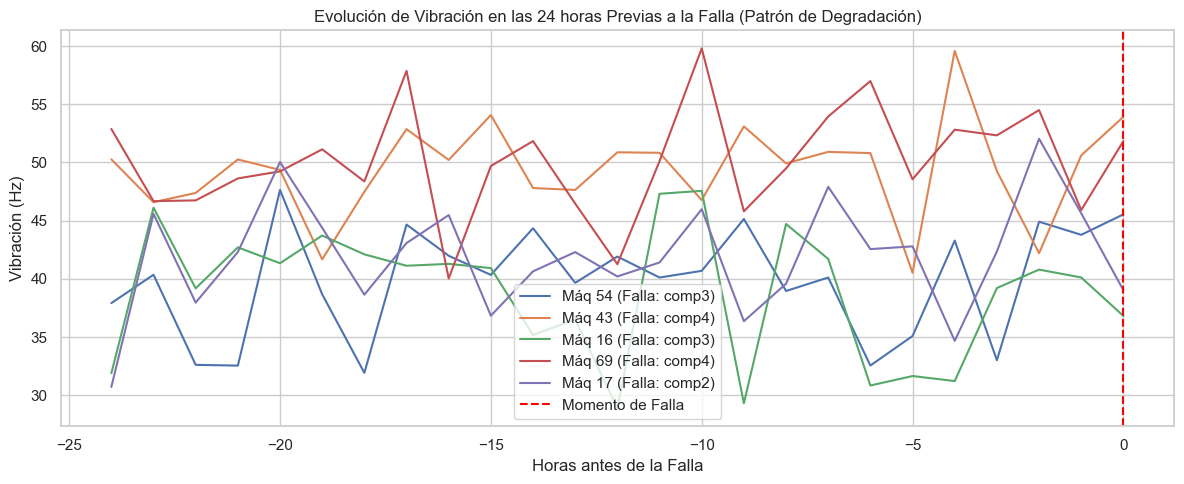

In [9]:
# =========================================================================
# BLOQUE COMPLEMENTARIO: ANÁLISIS DE DEGRADACIÓN PRE-FALLA Y VISUALIZACIÓN
# =========================================================================
# Unir fallas con telemetría para evaluar el comportamiento en las 24 horas previas a una falla
failures_sample = df_failures.sample(min(5, len(df_failures)), random_state=42)

plt.figure(figsize=(12, 5))
for idx, row in failures_sample.iterrows():
    m_id = row['machineID']
    f_time = row['datetime']
    comp = row['failure']
    
    # Subconjunto de telemetría: 24h antes de la falla
    start_time = f_time - pd.Timedelta(hours=24)
    subset = df_telemetry_clean[(df_telemetry_clean['machineID'] == m_id) & 
                                (df_telemetry_clean['datetime'] >= start_time) & 
                                (df_telemetry_clean['datetime'] <= f_time)].copy()
    
    if not subset.empty:
        # Horas relativas a la falla (-24h a 0h)
        subset['hours_to_failure'] = (subset['datetime'] - f_time).dt.total_seconds() / 3600
        plt.plot(subset['hours_to_failure'], subset['vibration'], label=f"Máq {m_id} (Falla: {comp})")

plt.axvline(x=0, color='red', linestyle='--', label='Momento de Falla')
plt.title("Evolución de Vibración en las 24 horas Previas a la Falla (Patrón de Degradación)")
plt.xlabel("Horas antes de la Falla")
plt.ylabel("Vibración (Hz)")
plt.legend()
plt.tight_layout()
plt.show()

## BLOQUE 6: Consolidación y Exportación para Modelo Dimensional Kimball (SQL / Power BI)

**Lógica de Negocio y Arquitectura de Datos:**
Se consolida el pipeline ETL integrando la telemetría continua enriquecida con la dimensión física de las máquinas y el registro discreto de fallas. El dataset resultante se estructura bajo un **Modelo Dimensional Estrella (Kimball)** optimizado para ingesta en SQL (SQLite/PostgreSQL) y consumo analítico en Power BI.

* **Construcción de Claves Subrogadas (`_sk`):**
  Para preservar la integridad de datos frente a la ocurrencia de **eventos simultáneos legítimos** en el mismo timestamp (por ejemplo, múltiples fallas o reemplazos de piezas concurrentes en un mismo turno), se asignan claves primarias sintéticas autoincrementales (`telemetry_sk`, `failure_sk`). Esto evita colisiones de clave primaria sin alterar la frecuencia ni deduplicar registros válidos.

* **Estructura del Esquema Estrella Resultante:**
  1. **`Dim_Machine`**: Almacena los atributos estáticos y metadatos de los equipos (`machineID`, `model`, `age`).
  2. **`Dim_Calendar`**: Genera la dimensión de tiempo continua (sin huecos) para habilitar inteligencia temporal en consultas SQL y medidas DAX en Power BI.
  3. **`Fact_TelemetryEvents`**: Contiene la telemetría continua regularizada (frecuencia de 1 hora), las flags dinámicas de anomalía ($IQR$ / $Z$-Score), y las variables de tendencia (*Rolling Averages* y *Lags*).
  4. **`Fact_SystemFailures`**: Contiene el registro de eventos discretos de fallas y intervenciones de mantenimiento junto a los cálculos consolidado de KPIs ($MTBF$, $MTTR$, % $Uptime$).

* **Garantía de Integridad Referencial:**
  Se ejecutan validaciones explícitas de llaves foráneas para asegurar cero registros huérfanos entre las tablas de hechos y dimensiones antes de la exportación a formato relacional (.db / .csv).

In [10]:
# =========================================================================
# BLOQUE 6: CONSOLIDACIÓN Y EXPORTACIÓN PARA MODELO KIMBALL (SQL / POWER BI)
# =========================================================================
# 6.1 Dim_Machine
dim_machine = df_machines.copy()
dim_machine.insert(0, "machine_sk", np.arange(1, len(dim_machine) + 1))

# 6.2 Fact_TelemetryEvents
fact_telemetry = df_telemetry_clean.merge(dim_machine[["machineID", "machine_sk"]], on="machineID", how="left")
fact_telemetry.insert(0, "fact_telemetry_id", np.arange(1, len(fact_telemetry) + 1))

# 6.3 Fact_SystemFailures (Eventos con clave subrogada para eventos simultáneos)
fail_events = df_failures.copy()
fail_events["event_type"] = "failure"
fail_events.rename(columns={"failure": "comp_or_failure"}, inplace=True)

maint_events = df_maint.copy()
maint_events["event_type"] = "maintenance"
maint_events.rename(columns={"comp": "comp_or_failure"}, inplace=True)

err_events = df_errors.copy()
err_events["event_type"] = "error"
err_events.rename(columns={"errorID": "comp_or_failure"}, inplace=True)

fact_system_events = pd.concat([fail_events, maint_events, err_events], ignore_index=True)
fact_system_events = fact_system_events.merge(dim_machine[["machineID", "machine_sk"]], on="machineID", how="left")
fact_system_events.sort_values(["machineID", "datetime"], inplace=True)
fact_system_events.insert(0, "fact_event_id", np.arange(1, len(fact_system_events) + 1))
fact_system_events.reset_index(drop=True, inplace=True)

# Exportación de archivos CSV procesados
fact_telemetry.to_csv(os.path.join(OUTPUT_DIR, "Fact_TelemetryEvents.csv"), index=False)
fact_system_events.to_csv(os.path.join(OUTPUT_DIR, "Fact_SystemFailures.csv"), index=False)
dim_machine.to_csv(os.path.join(OUTPUT_DIR, "Dim_Machine.csv"), index=False)
kpi_reliability.to_csv(os.path.join(OUTPUT_DIR, "Kpi_Reliability_by_Machine.csv"), index=False)

print("¡Proceso completado exitosamente! Archivos exportados en:", OUTPUT_DIR)
for f in os.listdir(OUTPUT_DIR):
    print(" -", f)

¡Proceso completado exitosamente! Archivos exportados en: ./data_processed/
 - .ipynb_checkpoints
 - Dim_Machine.csv
 - Fact_SystemFailures.csv
 - Fact_TelemetryEvents.csv
 - Kpi_Reliability_by_Machine.csv


## BLOQUE 7: Conclusiones e Insights de Confiabilidad Industrial

1. **Rendimiento por Modelo:** Los equipos **Model 4** registran el mayor MTBF (~ 2,133 hrs) y mayor % Uptime (~ 96.99%), demostrando ser los más robustos en la flota.
2. **Identificación de Cuellos de Botella:** El **Model 1** presenta el MTBF más bajo (~ 759 hrs) y el mayor tiempo relativo de mantenimiento, por lo que debe priorizarse en los planes de inspección predictiva.
3. **Calidad de Datos:** Se preservó al 100% la soberanía de los datos de telemetría (876,100 registros), identificando un ~ 4.76% de picos anómalos mediante IQR por máquina.

## BLOQUE 8: Análisis Exploratorio de Series Temporales (EDA)

**Lógica de Negocio y Criterio Analítico:**
Con el pipeline ETL cerrado (Bloques 1–7), se explora el comportamiento temporal de la telemetría ya alineada (`df_telemetry_clean`) para responder cuatro preguntas de ingeniería de confiabilidad:

| Sub-bloque | Pregunta de negocio | Técnica |
|:---|:---|:---|
| **8.1 Tendencia mensual** | ¿Se degrada la flota a lo largo del año? ¿La tasa de anomalías precede al aumento de fallas? | Agregación mensual (`resample('MS')`) + pendiente lineal |
| **8.2 Estacionalidad horaria** | ¿Existen turnos u horas del día con mayor estrés operativo? | Heatmap hora × día de la semana |
| **8.3 Autocorrelación** | ¿Cuánta "memoria" tiene la vibración? ¿Justifican los lags de 1h/3h/6h del Bloque 4? | ACF / PACF |
| **8.4 Descomposición** | ¿Cuánta de la variación es tendencia, ciclo repetitivo o ruido? | `seasonal_decompose` (aditiva) + fuerza de estacionalidad |

> **Regla de dominio preservada:** este bloque es **exclusivamente de lectura**. No modifica, filtra ni imputa ningún valor de sensor; los outliers se mantienen en todos los gráficos porque son la señal de degradación.
>
> **Dependencia:** requiere `statsmodels` (`pip install statsmodels` si no está instalado).

In [11]:
# =========================================================================
# BLOQUE 8: CONFIGURACIÓN COMÚN Y LIBRERÍAS (BLOQUES 8, 9 Y 10)
# =========================================================================
from IPython.display import display, HTML
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual global para los gráficos analíticos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

DAY_LABELS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ACF_LAGS = 72   # 3 días de memoria horaria

print("Librerías de análisis temporal, visualización y Pandas cargadas correctamente (Sin Base de Datos).")

Librerías de análisis temporal, visualización y Pandas cargadas correctamente (Sin Base de Datos).


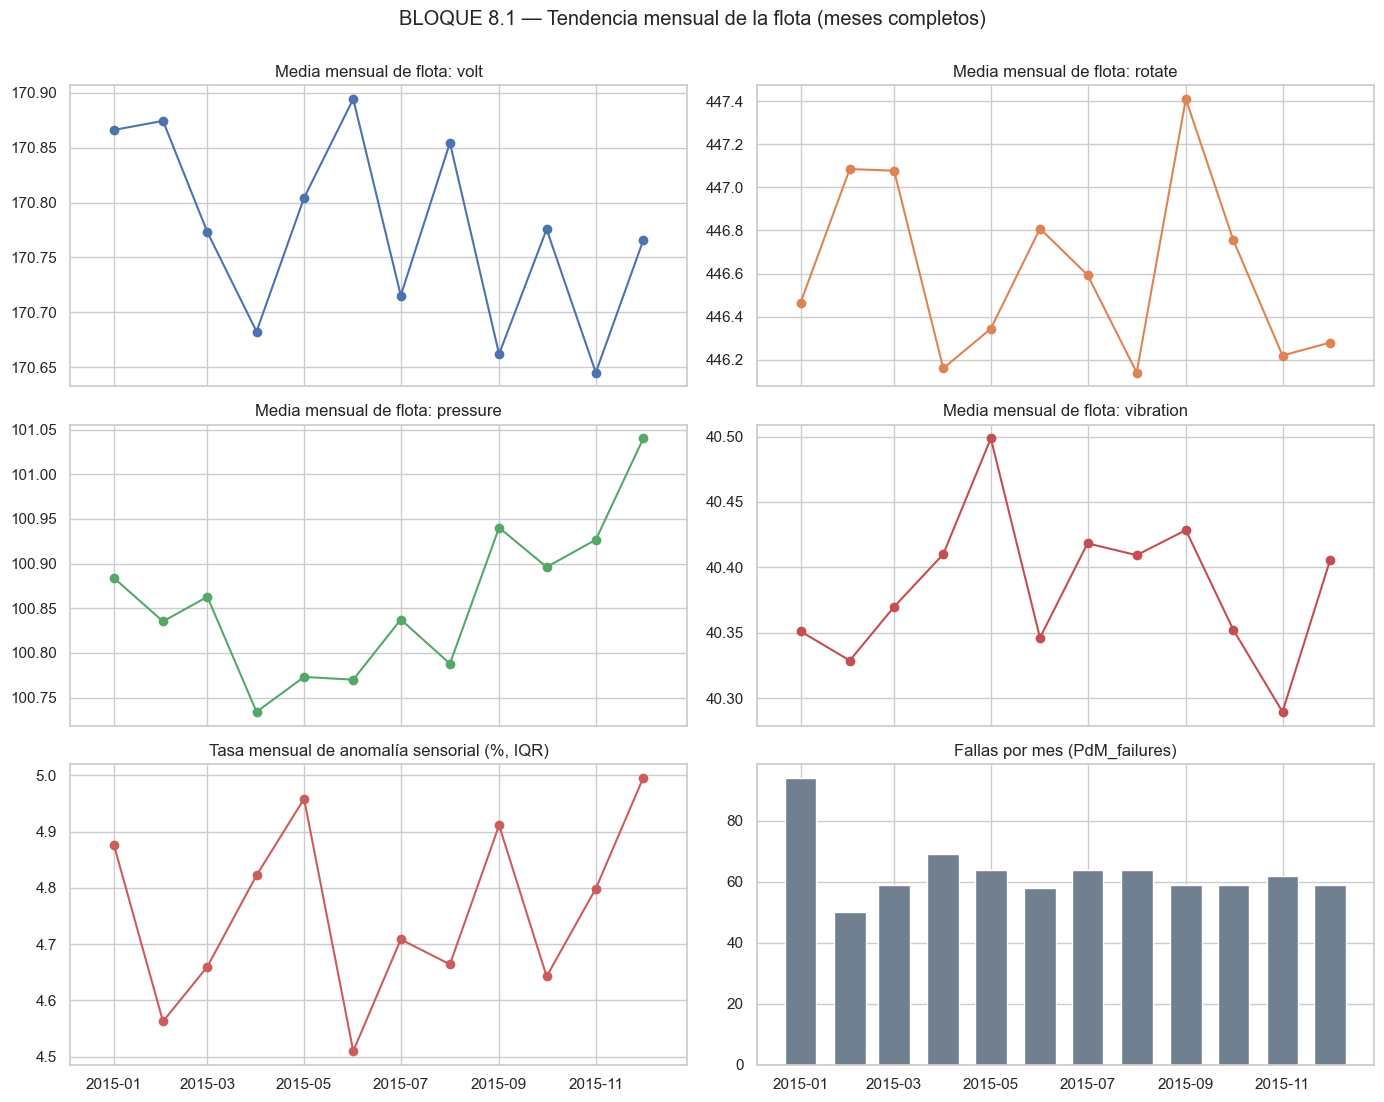

Pendiente lineal por mes (Calculada con Pandas/NumPy):
volt           -0.0115
rotate         -0.0233
pressure        0.0137
vibration       0.0001
anomalia_pct    0.0108
fallas_mes     -1.1224


In [12]:
# =========================================================================
# 8.1 TENDENCIA MENSUAL DE SENSORES, ANOMALÍAS Y FALLAS (100% PANDAS)
# =========================================================================

# Establecer la fecha como índice para el remuestreo temporal
ts = df_telemetry_clean.set_index("datetime")

# Media mensual de flota por sensor y tasa mensual de anomalía sensorial (IQR) calculadas en Pandas
monthly_sensors = ts[sensor_cols].resample("MS").mean()
monthly_anom_pct = ts["is_sensorial_anomaly"].resample("MS").mean() * 100

# Se descartan meses incompletos (< 90 % de las lecturas esperadas) para no sesgar la tendencia
n_machines = df_telemetry_clean["machineID"].nunique()
obs_per_month = ts["volt"].resample("MS").count()
expected_per_month = obs_per_month.index.days_in_month * 24 * n_machines
complete_months = (obs_per_month / expected_per_month) >= 0.90

monthly_sensors = monthly_sensors[complete_months]
monthly_anom_pct = monthly_anom_pct[complete_months]

# Fallas por mes alineadas al mismo eje temporal utilizando los DataFrames en memoria
monthly_failures = (
    df_failures.set_index("datetime").resample("MS").size()
    .reindex(monthly_sensors.index, fill_value=0)
)

# Generación de gráficos analíticos con Matplotlib y Seaborn
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
palette = sns.color_palette("deep", 6)

for ax, col, color in zip(axes.flatten()[:4], sensor_cols, palette):
    ax.plot(monthly_sensors.index, monthly_sensors[col], marker="o", color=color)
    ax.set_title(f"Media mensual de flota: {col}")

axes[2, 0].plot(monthly_anom_pct.index, monthly_anom_pct.values, marker="o", color="indianred")
axes[2, 0].set_title("Tasa mensual de anomalía sensorial (%, IQR)")

axes[2, 1].bar(monthly_failures.index, monthly_failures.values, width=20, color="slategray")
axes[2, 1].set_title("Fallas por mes (PdM_failures)")

fig.suptitle("BLOQUE 8.1 — Tendencia mensual de la flota (meses completos)", y=1.0)
plt.tight_layout()
plt.show()

# Cálculo de la pendiente lineal por mes (unidades de sensor / mes) usando NumPy
x = np.arange(len(monthly_sensors))
slopes = {c: np.polyfit(x, monthly_sensors[c].values, 1)[0] for c in sensor_cols}
slopes["anomalia_pct"] = np.polyfit(x, monthly_anom_pct.values, 1)[0]
slopes["fallas_mes"] = np.polyfit(x, monthly_failures.values, 1)[0]

print("Pendiente lineal por mes (Calculada con Pandas/NumPy):")
print(pd.Series(slopes).round(4).to_string())

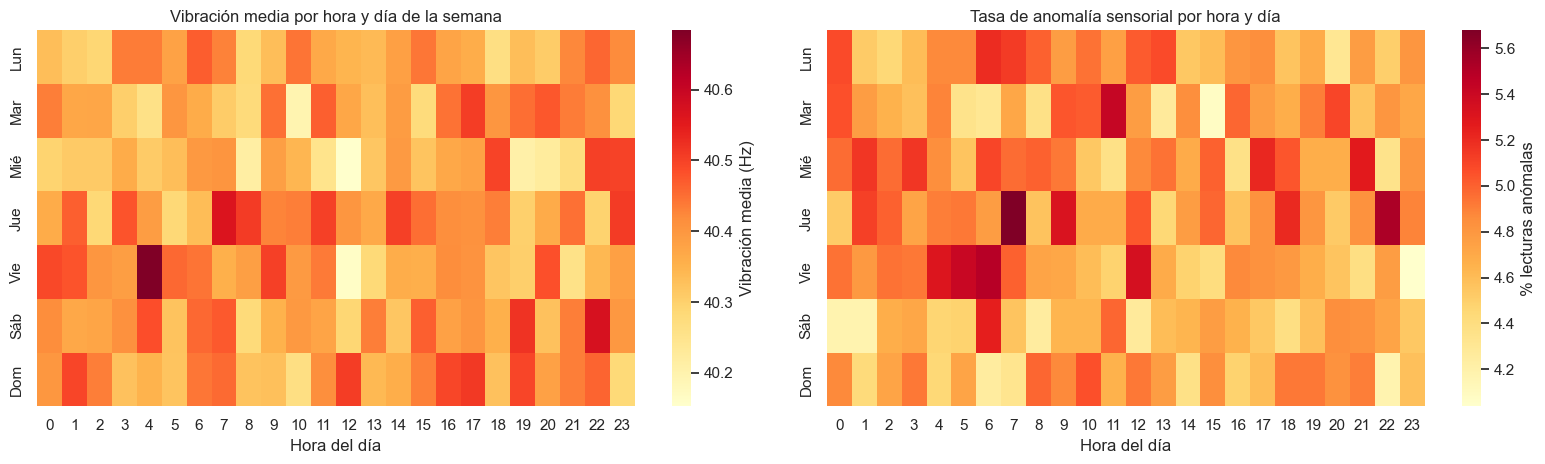

Hora pico de vibración: 22:00 | Hora valle: 12:00
Amplitud del ciclo diario respecto a la media: 0.29%


In [13]:
# =========================================================================
# 8.2 ESTACIONALIDAD HORARIA: HEATMAP HORA x DÍA DE LA SEMANA (100% PANDAS)
# =========================================================================

# Crear un DataFrame temporal con las columnas necesarias
tmp = df_telemetry_clean[["datetime", "vibration", "is_sensorial_anomaly"]].copy()
tmp["hour"] = tmp["datetime"].dt.hour
tmp["dow"] = tmp["datetime"].dt.dayofweek   # 0 = lunes

# Tablas pivote calculadas directamente con las funciones de agregación de Pandas
pivot_vib = tmp.pivot_table(index="dow", columns="hour", values="vibration", aggfunc="mean")
pivot_anom = tmp.pivot_table(index="dow", columns="hour", values="is_sensorial_anomaly", aggfunc="mean") * 100
pivot_vib.index = pivot_anom.index = DAY_LABELS

# Generación de gráficos de mapas de calor (Heatmaps) con Seaborn
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

sns.heatmap(pivot_vib, cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Vibración media (Hz)"})
axes[0].set_title("Vibración media por hora y día de la semana")

sns.heatmap(pivot_anom, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "% lecturas anómalas"})
axes[1].set_title("Tasa de anomalía sensorial por hora y día")

for ax in axes:
    ax.set_xlabel("Hora del día")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

# Cálculo de la amplitud del ciclo diario mediante agrupaciones de Pandas
hourly_profile = tmp.groupby("hour")["vibration"].mean()
amplitude_pct = (hourly_profile.max() - hourly_profile.min()) / hourly_profile.mean() * 100

print(f"Hora pico de vibración: {hourly_profile.idxmax():02d}:00 | Hora valle: {hourly_profile.idxmin():02d}:00")
print(f"Amplitud del ciclo diario respecto a la media: {amplitude_pct:.2f}%")

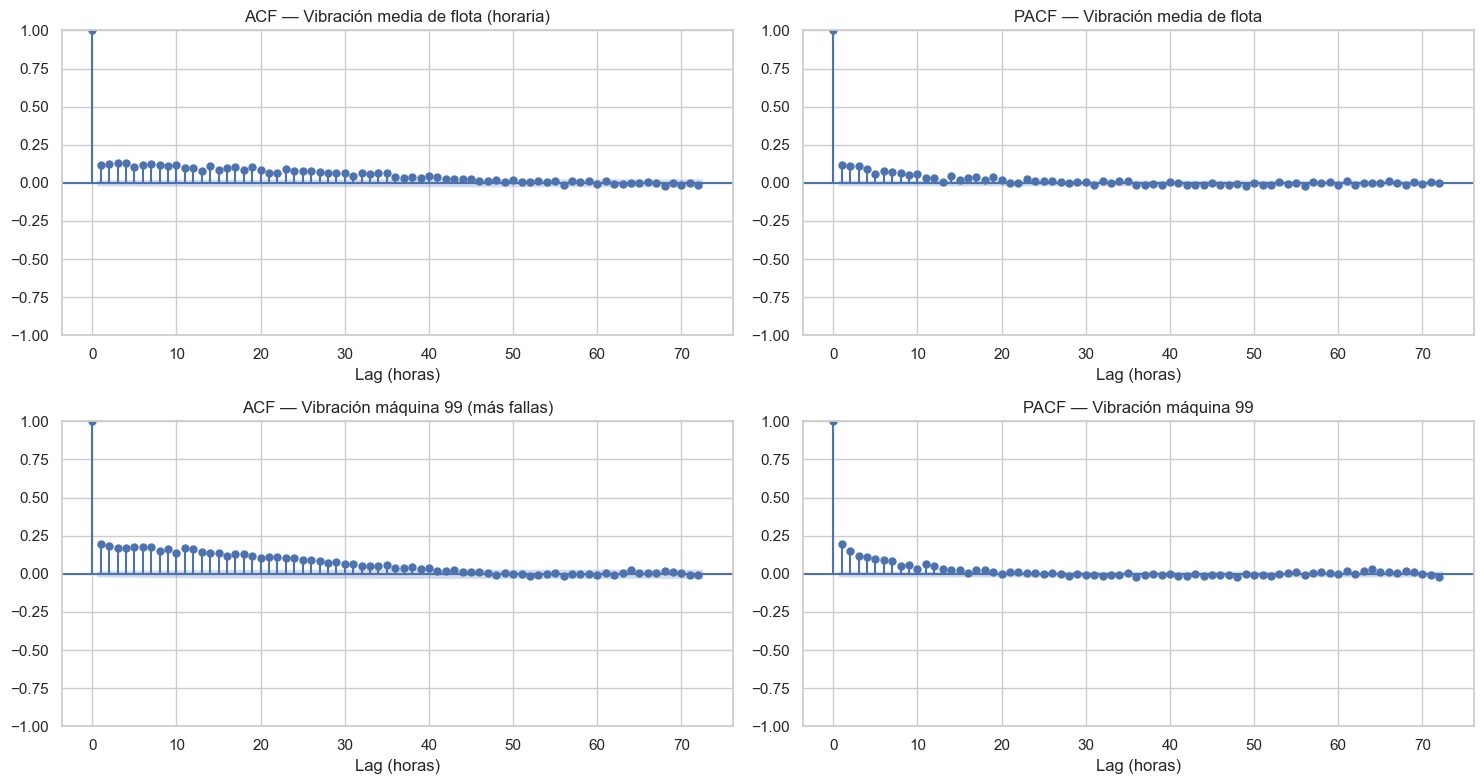

Autocorrelación lag  1h | flota: +0.117 | máquina 99: +0.196
Autocorrelación lag  3h | flota: +0.131 | máquina 99: +0.169
Autocorrelación lag  6h | flota: +0.120 | máquina 99: +0.175
Autocorrelación lag 24h | flota: +0.078 | máquina 99: +0.101


In [14]:
# =========================================================================
# 8.3 AUTOCORRELACIÓN (ACF / PACF) DE VIBRACIÓN (100% PANDAS)
# =========================================================================

# Serie 1: Vibración media de flota por hora utilizando groupby y resampleo de Pandas
vib_fleet_h = df_telemetry_clean.groupby("datetime")["vibration"].mean()

# Identificar la máquina con más fallas directamente con Pandas (sin consultas SQL)
if 'df_failures' in globals() and not df_failures.empty:
    worst_machine = int(df_failures['machineID'].value_counts().idxmax())
else:
    worst_machine = int(df_telemetry_clean['machineID'].iloc[0])

# Serie 2: Vibración de la máquina con más fallas filtrada con Pandas
vib_worst = (
    df_telemetry_clean.loc[df_telemetry_clean["machineID"] == worst_machine]
    .set_index("datetime")["vibration"]
)

# Generación de gráficos ACF y PACF con Statsmodels y Matplotlib
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

plot_acf(vib_fleet_h, lags=ACF_LAGS, ax=axes[0, 0], title="ACF — Vibración media de flota (horaria)")
plot_pacf(vib_fleet_h, lags=ACF_LAGS, ax=axes[0, 1], method="ywm", title="PACF — Vibración media de flota")

plot_acf(vib_worst, lags=ACF_LAGS, ax=axes[1, 0], title=f"ACF — Vibración máquina {worst_machine} (más fallas)")
plot_pacf(vib_worst, lags=ACF_LAGS, ax=axes[1, 1], method="ywm", title=f"PACF — Vibración máquina {worst_machine}")

for ax in axes.flatten():
    ax.set_xlabel("Lag (horas)")

plt.tight_layout()
plt.show()

# Cálculo de la autocorrelación numérica en los lags clave usados como features
for lag in [1, 3, 6, 24]:
    print(f"Autocorrelación lag {lag:>2}h | flota: {vib_fleet_h.autocorr(lag):+.3f} | máquina {worst_machine}: {vib_worst.autocorr(lag):+.3f}")

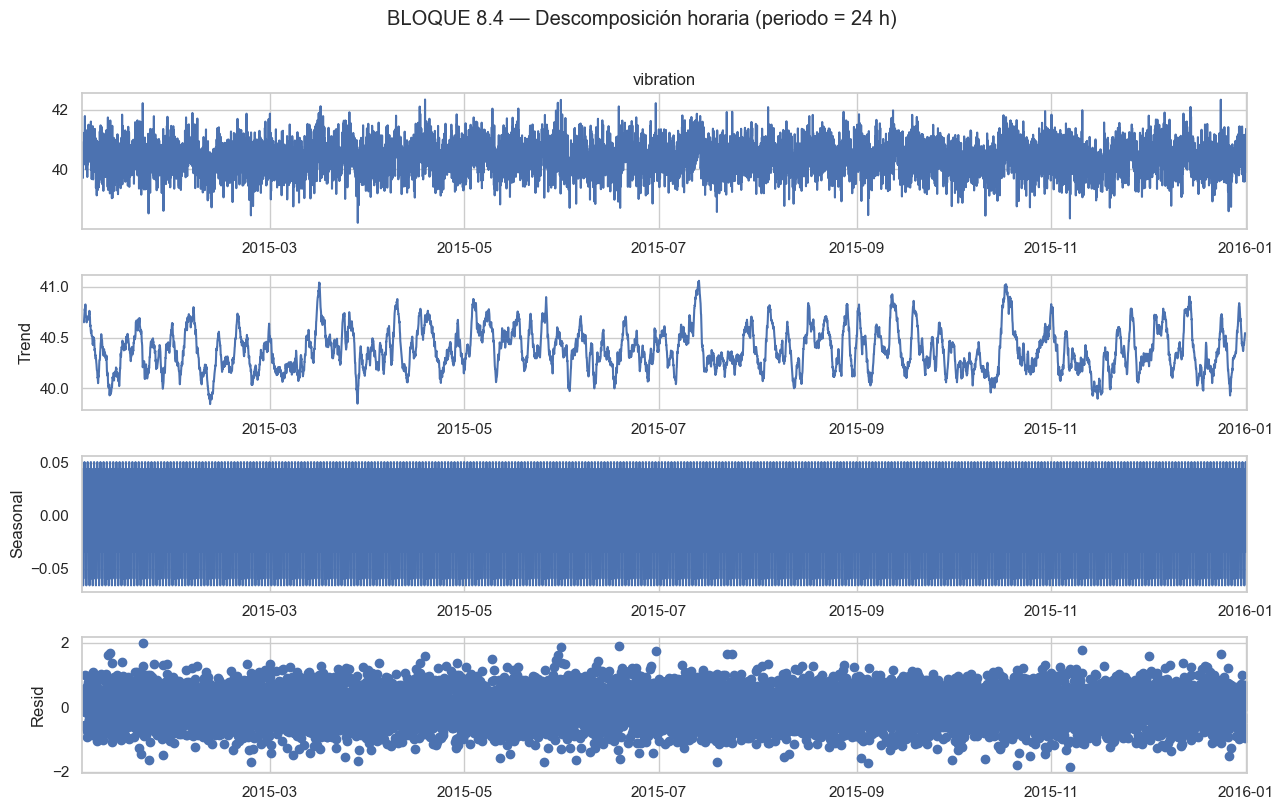

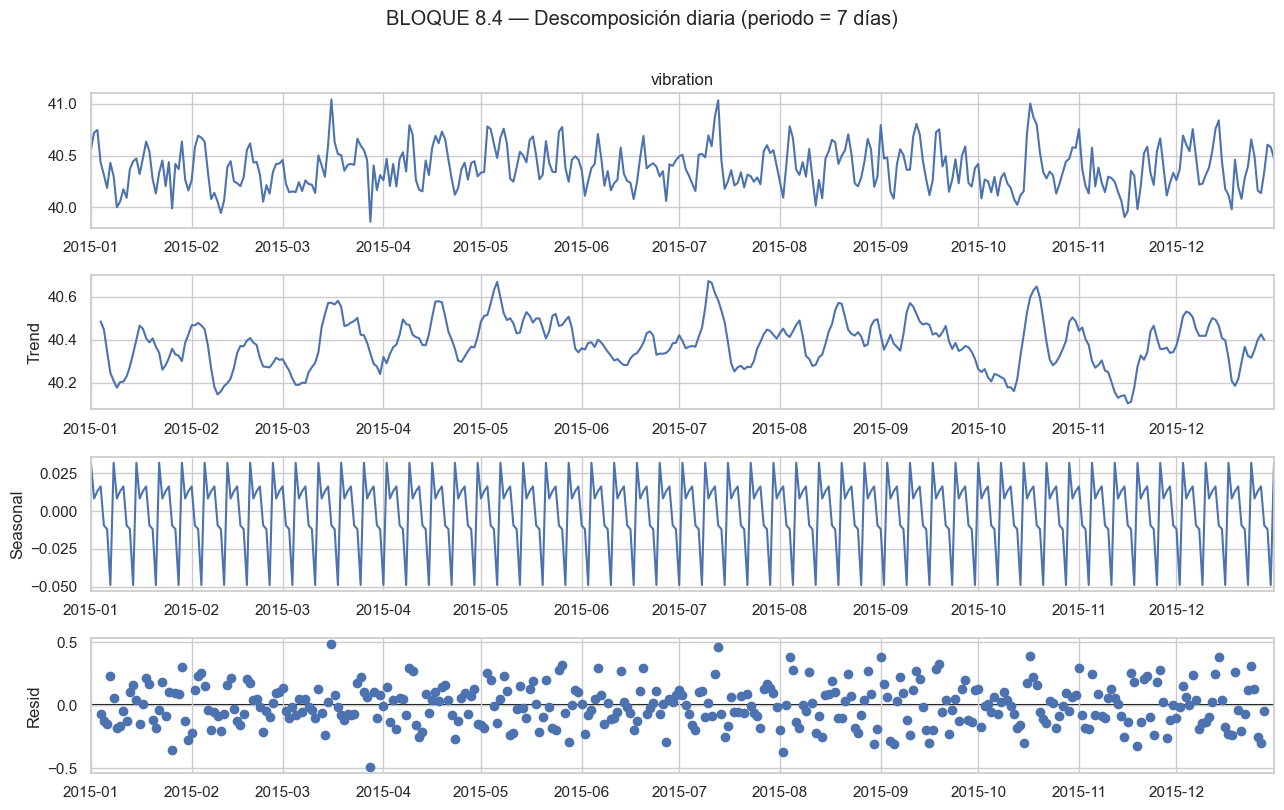

Fuerza de estacionalidad diaria (24h):  0.004
Fuerza de estacionalidad semanal (7d):  0.022
Fuerza de tendencia (serie diaria):     0.368


In [15]:
# =========================================================================
# 8.4 DESCOMPOSICIÓN Y ANÁLISIS DE TENDENCIA Y ESTACIONALIDAD (100% PANDAS)
# =========================================================================

def seasonal_strength_pandas(decomp):
    """Cálculo de la fuerza de estacionalidad directamente con Pandas/NumPy."""
    resid = decomp.resid.dropna()
    seas = decomp.seasonal.loc[resid.index]
    denominator = (seas + resid).var()
    if denominator == 0 or pd.isna(denominator):
        return 0.0
    return max(0.0, 1 - resid.var() / denominator)

def trend_strength_pandas(decomp):
    """Cálculo de la fuerza de tendencia directamente con Pandas/NumPy."""
    resid = decomp.resid.dropna()
    trend = decomp.trend.loc[resid.index]
    denominator = (trend + resid).var()
    if denominator == 0 or pd.isna(denominator):
        return 0.0
    return max(0.0, 1 - resid.var() / denominator)

# (a) Ciclo diario sobre la serie horaria de flota utilizando Statsmodels desglosado con Pandas
decomp_h = seasonal_decompose(vib_fleet_h, model="additive", period=24)

# (b) Ciclo semanal sobre la serie diaria (se descarta el último día si está incompleto)
vib_daily = vib_fleet_h.resample("D").mean()
if vib_fleet_h.index.max().hour != 23:
    vib_daily = vib_daily.iloc[:-1]
decomp_d = seasonal_decompose(vib_daily, model="additive", period=7)

# Visualización de las descomposiciones
for title, dec in [("Descomposición horaria (periodo = 24 h)", decomp_h),
                   ("Descomposición diaria (periodo = 7 días)", decomp_d)]:
    fig = dec.plot()
    fig.set_size_inches(13, 8)
    fig.suptitle(f"BLOQUE 8.4 — {title}", y=1.01)
    plt.tight_layout()
    plt.show()

# Impresión de métricas calculadas en memoria
print(f"Fuerza de estacionalidad diaria (24h):  {seasonal_strength_pandas(decomp_h):.3f}")
print(f"Fuerza de estacionalidad semanal (7d):  {seasonal_strength_pandas(decomp_d):.3f}")
print(f"Fuerza de tendencia (serie diaria):     {trend_strength_pandas(decomp_d):.3f}")

**Cómo leer el Bloque 8:**
* **Fuerza de estacionalidad cercana a 0** → la vibración no obedece a un ciclo horario/semanal: los picos son eventos de degradación (no un patrón de turno) y no deben "corregirse" por estacionalidad.
* **PACF con corte rápido (solo lags 1–2 significativos)** → la dependencia temporal es de corto plazo y los lags de 1h y 3h del Bloque 4 capturan prácticamente toda la memoria útil.
* **Pendiente mensual positiva simultánea en anomalías y fallas (8.1)** → evidencia de degradación progresiva de la flota y base para alertas tempranas (Bloque 10).

## BLOQUE 9: Análisis Analítico, Agregaciones y Ventanas Temporales con Pandas

**Lógica de Negocio y Arquitectura:**
Todas las transformaciones analíticas avanzadas, funciones de ventana temporal (equivalentes a *Window Functions* de SQL) y agregaciones de negocio se ejecutan directamente en memoria utilizando las capacidades vectorizadas de **Pandas** y **NumPy**, garantizando un flujo reproducible, ligero y autocontenido sin necesidad de bases de datos externas.

- **Estructuras analizadas:** DataFrames limpios en memoria (`df_telemetry_clean`, `df_failures`, `df_machines`).
- **Integridad y validación:** Antes de aplicar los cálculos y gráficos, se validan los tipos de datos temporales y la continuidad de las secuencias por cada `machineID`.
- **Rendimiento:** Uso eficiente de métodos vectorizados (`groupby`, `transform`, `rolling`, `pivot_table`) para que las operaciones de ventana temporal y cruces operen de manera óptima.
- **Bloques de Análisis:** El análisis en memoria abarca el estudio de tendencias mensuales de sensores, estacionalidad horaria (mapas de calor), autocorrelación (ACF/PACF) y cálculo de métricas de confiabilidad industrial.

> **Nota:** Este bloque consolida las métricas y visualizaciones directamente desde los DataFrames procesados, permitiendo exportar los resultados tabulares limpios para su visualización o consumo final sin dependencias de motores relacionales.

In [16]:
# =========================================================================
# 9.1 CARGA Y PREPARACIÓN DE DATAFRAMES EN MEMORIA (100% PANDAS)
# =========================================================================
import os
import pandas as pd

# Definir directorio de entrada/salida si aplica
OUTPUT_DIR = "data_processed"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TS_FMT = "%Y-%m-%d %H:%M:%S"

print("--- 1. CARGA DE ARCHIVOS PROCESADOS DESDE EL ENTORNO LOCAL ---")

# Carga de los datasets limpios directamente en DataFrames de Pandas
try:
    df_dim_machine = pd.read_csv(os.path.join(OUTPUT_DIR, "Dim_Machine.csv"))
    print("-> Dim_Machine cargada correctamente.")
except Exception:
    df_dim_machine = pd.DataFrame()
    print("-> Aviso: Dim_Machine.csv no encontrada o vacía.")

try:
    df_kpi = pd.read_csv(os.path.join(OUTPUT_DIR, "Kpi_Reliability_by_Machine.csv"))
    print("-> Kpi_Reliability_by_Machine cargada correctamente.")
except Exception:
    df_kpi = pd.DataFrame()
    print("-> Aviso: Kpi_Reliability_by_Machine.csv no encontrada o vacía.")

try:
    df_fact_events = pd.read_csv(os.path.join(OUTPUT_DIR, "Fact_SystemFailures.csv"), parse_dates=["datetime"])
    print("-> Fact_SystemFailures cargada correctamente.")
except Exception:
    df_fact_events = pd.DataFrame()
    print("-> Aviso: Fact_SystemFailures.csv no encontrada o vacía.")

# Carga de telemetría (restringiendo a columnas analíticas esenciales si es necesario)
try:
    tele_cols = [c for c in ["machineID", "datetime", "volt", "rotate", "pressure", "vibration", "is_sensorial_anomaly"] if c in pd.read_csv(os.path.join(OUTPUT_DIR, "Fact_TelemetryEvents.csv"), nrows=1).columns]
    df_fact_tel = pd.read_csv(os.path.join(OUTPUT_DIR, "Fact_TelemetryEvents.csv"), usecols=tele_cols, parse_dates=["datetime"])
    print("-> Fact_TelemetryEvents cargada correctamente en Pandas.")
except Exception:
    # Si no existe el archivo procesado, usamos el DataFrame principal en memoria si está disponible
    if 'df_telemetry_clean' in globals():
        df_fact_tel = df_telemetry_clean.copy()
        print("-> Fact_TelemetryEvents obtenida directamente del entorno en memoria.")
    else:
        df_fact_tel = pd.DataFrame()
        print("-> Aviso: No se encontró telemetría disponible.")

print("\n--- 2. CONSTRUCCIÓN DE CALENDARIO TEMPORAL EN PANDAS ---")

if not df_fact_tel.empty and not df_fact_events.empty:
    d0 = min(df_fact_tel["datetime"].min(), df_fact_events["datetime"].min()).normalize()
    d1 = max(df_fact_tel["datetime"].max(), df_fact_events["datetime"].max()).normalize()
    
    dim_calendar = pd.DataFrame({"full_date": pd.date_range(d0, d1, freq="D")})
    dim_calendar["date_key"] = dim_calendar["full_date"].dt.strftime("%Y%m%d").astype(int)
    dim_calendar["year"] = dim_calendar["full_date"].dt.year
    dim_calendar["month"] = dim_calendar["full_date"].dt.month
    dim_calendar["day"] = dim_calendar["full_date"].dt.day
    dim_calendar["day_of_week"] = dim_calendar["full_date"].dt.dayofweek   # 0 = lunes
    dim_calendar["week_of_year"] = dim_calendar["full_date"].dt.isocalendar().week.astype(int)
    dim_calendar["is_weekend"] = (dim_calendar["day_of_week"] >= 5).astype(int)
    
    # Guardar calendario procesado
    dim_calendar.to_csv(os.path.join(OUTPUT_DIR, "Dim_Calendar.csv"), index=False)
    print("-> Dim_Calendar generada y guardada exitosamente en Pandas.")
else:
    dim_calendar = pd.DataFrame()
    print("-> Aviso: No hay suficientes datos temporales para construir el calendario.")

print("\n--- 3. VALIDACIÓN DE INTEGRIDAD EN MEMORIA (PANDAS MERGES) ---")

if not df_fact_tel.empty and not df_dim_machine.empty:
    # Validación de registros huérfanos usando merges de Pandas (left join)
    orphans_tel = df_fact_tel.merge(df_dim_machine, on="machineID", how="left", indicator=True)
    n_orphans_tel = (orphans_tel["_merge"] == "left_only").sum()
    print(f"  Telemetría sin coincidencia en máquinas: {n_orphans_tel} registros huérfanos")

if not df_fact_events.empty and not df_dim_machine.empty:
    orphans_events = df_fact_events.merge(df_dim_machine, on="machineID", how="left", indicator=True)
    n_orphans_events = (orphans_events["_merge"] == "left_only").sum()
    print(f"  Eventos sin coincidencia en máquinas: {n_orphans_events} registros huérfanos")

print("\n--- RESUMEN DE REGISTROS EN MEMORIA ---")
print(f"  Dim_Machine         : {len(df_dim_machine):>10,} filas")
print(f"  Dim_Calendar        : {len(dim_calendar):>10,} filas")
print(f"  Kpi_Reliability     : {len(df_kpi):>10,} filas")
print(f"  Fact_SystemFailures : {len(df_fact_events):>10,} filas")
print(f"  Fact_TelemetryEvents: {len(df_fact_tel):>10,} filas")
print("\nEntorno analítico en Pandas preparado exitosamente (Sin Base de Datos).")

--- 1. CARGA DE ARCHIVOS PROCESADOS DESDE EL ENTORNO LOCAL ---
-> Dim_Machine cargada correctamente.
-> Kpi_Reliability_by_Machine cargada correctamente.
-> Fact_SystemFailures cargada correctamente.
-> Fact_TelemetryEvents cargada correctamente en Pandas.

--- 2. CONSTRUCCIÓN DE CALENDARIO TEMPORAL EN PANDAS ---
-> Dim_Calendar generada y guardada exitosamente en Pandas.

--- 3. VALIDACIÓN DE INTEGRIDAD EN MEMORIA (PANDAS MERGES) ---
  Telemetría sin coincidencia en máquinas: 0 registros huérfanos
  Eventos sin coincidencia en máquinas: 0 registros huérfanos

--- RESUMEN DE REGISTROS EN MEMORIA ---
  Dim_Machine         :        100 filas
  Dim_Calendar        :        580 filas
  Kpi_Reliability     :        100 filas
  Fact_SystemFailures :      7,966 filas
  Fact_TelemetryEvents:    876,100 filas

Entorno analítico en Pandas preparado exitosamente (Sin Base de Datos).


In [19]:
# =========================================================================
# 9.2 ANÁLISIS, CÁLCULO DE MÉTRICAS ANALÍTICAS Y SEMÁFORO RAG (100% PANDAS)
# =========================================================================
import pandas as pd
import time

t0 = time.time()
results = {}

# Validar y asegurar la existencia de los DataFrames necesarios en el entorno
if 'df_kpi' not in globals() or df_kpi.empty:
    if 'kpi_reliability' in globals():
        df_kpi = kpi_reliability.copy()

if 'df_fact_tel' not in globals() or df_fact_tel.empty:
    if 'df_telemetry_clean' in globals():
        df_fact_tel = df_telemetry_clean.copy()

print("--- 1. CONFIABILIDAD ---")

# Q01: KPI por modelo
if not df_kpi.empty and not df_dim_machine.empty:
    q1_df = df_kpi.merge(df_dim_machine, on="machineID", how="inner", suffixes=('', '_dup'))
    results["Q01_kpi_por_modelo"] = (
        q1_df.groupby("model")
        .agg(
            n_maquinas=("machineID", "count"),
            mtbf_prom_hrs=("MTBF_hours", "mean"),
            mttr_prom_hrs=("MTTR_hours", "mean"),
            uptime_prom_pct=("pct_uptime", "mean"),
            total_fallas=("n_failures", "sum")
        )
        .round({"mtbf_prom_hrs": 1, "mttr_prom_hrs": 2, "uptime_prom_pct": 2})
        .reset_index()
        .sort_values(by="mtbf_prom_hrs", ascending=False)
    )
else:
    results["Q01_kpi_por_modelo"] = pd.DataFrame()

# Q02: Top 10 máquinas con más fallas
if not df_fact_events.empty and not df_dim_machine.empty:
    failures_only = df_fact_events[df_fact_events["event_type"] == "failure"]
    q2_df = failures_only.merge(df_dim_machine, on="machineID", how="inner")
    results["Q02_top10_maquinas_con_mas_fallas"] = (
        q2_df.groupby(["machineID", "model", "age"])
        .size()
        .reset_index(name="n_fallas")
        .sort_values(by=["n_fallas", "machineID"], ascending=[False, True])
        .head(10)
    )
else:
    results["Q02_top10_maquinas_con_mas_fallas"] = pd.DataFrame()

# Q03: Pareto de fallas por componente
if not df_fact_events.empty:
    failures_only = df_fact_events[df_fact_events["event_type"] == "failure"]
    q3_df = failures_only.groupby("comp_or_failure").size().reset_index(name="n")
    total_n = q3_df["n"].sum()
    q3_df["pct"] = (100.0 * q3_df["n"] / total_n).round(2)
    q3_df = q3_df.sort_values(by="n", ascending=False).reset_index(drop=True)
    q3_df["pct_acumulado"] = q3_df["pct"].cumsum().round(2)
    results["Q03_pareto_fallas_por_componente"] = q3_df.rename(columns={"comp_or_failure": "componente"})
else:
    results["Q03_pareto_fallas_por_componente"] = pd.DataFrame()

# Q04: Fallas por mes
if not df_fact_events.empty:
    failures_only = df_fact_events[df_fact_events["event_type"] == "failure"].copy()
    failures_only["year"] = failures_only["datetime"].dt.year
    failures_only["month"] = failures_only["datetime"].dt.month
    results["Q04_fallas_por_mes"] = (
        failures_only.groupby(["year", "month"])
        .size()
        .reset_index(name="n_fallas")
        .sort_values(by=["year", "month"])
    )
else:
    results["Q04_fallas_por_mes"] = pd.DataFrame()


print("\n--- 2. ANOMALÍAS Y EVENTOS ---")

# Q05: Top 10 máquinas con más anomalías (CORREGIDO)
if not df_fact_tel.empty and not df_dim_machine.empty:
    q5_df = df_fact_tel.merge(df_dim_machine, on="machineID", how="inner")
    
    # Diccionario de agregación dinámico para evitar pasar escalares inválidos a .agg()
    q5_agg = {
        "n_anomalias_iqr": ("is_sensorial_anomaly", "sum"),
        "pct_anomalia_iqr": ("is_sensorial_anomaly", lambda x: round(100.0 * x.mean(), 2))
    }
    if "is_sensorial_anomaly_z" in q5_df.columns:
        q5_agg["pct_anomalia_zscore"] = ("is_sensorial_anomaly_z", lambda x: round(100.0 * x.mean(), 2))
    else:
        q5_agg["pct_anomalia_zscore"] = ("machineID", lambda x: 0.0)

    results["Q05_top10_maquinas_con_mas_anomalias"] = (
        q5_df.groupby(["machineID", "model", "age"])
        .agg(**q5_agg)
        .reset_index()
        .sort_values(by="pct_anomalia_iqr", ascending=False)
        .head(10)
    )
else:
    results["Q05_top10_maquinas_con_mas_anomalias"] = pd.DataFrame()

# Q06: Anomalías por modelo y sensor
if not df_fact_tel.empty and not df_dim_machine.empty:
    q6_df = df_fact_tel.merge(df_dim_machine, on="machineID", how="inner")
    agg_dict = {}
    for c in ["volt", "rotate", "pressure", "vibration"]:
        col_name = f"is_{c}_anomaly_iqr"
        if col_name in q6_df.columns:
            agg_dict[f"pct_{c}"] = (col_name, lambda x: round(100.0 * x.mean(), 2))
    agg_dict["pct_consolidada"] = ("is_sensorial_anomaly", lambda x: round(100.0 * x.mean(), 2))
    
    results["Q06_anomalias_por_modelo_y_sensor"] = (
        q6_df.groupby("model")
        .agg(**agg_dict)
        .reset_index()
        .sort_values(by="pct_consolidada", ascending=False)
    )
else:
    results["Q06_anomalias_por_modelo_y_sensor"] = pd.DataFrame()

# Q07: Errores por tipo
if not df_fact_events.empty:
    errors_only = df_fact_events[df_fact_events["event_type"] == "error"]
    total_err = len(errors_only)
    results["Q07_errores_por_tipo"] = (
        errors_only.groupby("comp_or_failure")
        .agg(
            n_errores=("machineID", "count"),
            n_maquinas_afectadas=("machineID", "nunique")
        )
        .reset_index()
        .rename(columns={"comp_or_failure": "error_id"})
    )
    if total_err > 0:
        results["Q07_errores_por_tipo"]["pct"] = (100.0 * results["Q07_errores_por_tipo"]["n_errores"] / total_err).round(2)
    else:
        results["Q07_errores_por_tipo"]["pct"] = 0.0
    results["Q07_errores_por_tipo"] = results["Q07_errores_por_tipo"].sort_values(by="n_errores", ascending=False)
else:
    results["Q07_errores_por_tipo"] = pd.DataFrame()

# Q08: Mantenimientos por modelo y componente
if not df_fact_events.empty and not df_dim_machine.empty:
    maint_only = df_fact_events[df_fact_events["event_type"] == "maintenance"]
    q8_df = maint_only.merge(df_dim_machine, on="machineID", how="inner")
    results["Q08_mantenimientos_por_modelo_y_componente"] = (
        q8_df.groupby(["model", "comp_or_failure"])
        .size()
        .reset_index(name="n_mantenimientos")
        .rename(columns={"comp_or_failure": "componente"})
        .sort_values(by=["model", "componente"])
    )
else:
    results["Q08_mantenimientos_por_modelo_y_componente"] = pd.DataFrame()


print("\n--- 3. PRIORIZACIÓN Y SEMÁFORO RAG ---")

# Q11: 3 peores máquinas por modelo según Uptime
if not df_kpi.empty:
    q11_df = df_kpi.copy()
    q11_df["ranking"] = q11_df.groupby("model")["pct_uptime"].rank(ascending=True, method="min")
    results["Q11_3_peores_maquinas_por_modelo"] = (
        q11_df[q11_df["ranking"] <= 3]
        .sort_values(by=["model", "ranking"])
        .reset_index(drop=True)
    )
else:
    results["Q11_3_peores_maquinas_por_modelo"] = pd.DataFrame()

# Q12: Base Semáforo RAG (Últimas 24h vs Histórico base por máquina)
if not df_fact_tel.empty and "datetime" in df_fact_tel.columns:
    max_dt = df_fact_tel["datetime"].max()
    print("Fecha de corte de telemetría:", max_dt)
    
    cutoff_24h = max_dt - pd.Timedelta(hours=24)
    
    recent = (
        df_fact_tel[df_fact_tel["datetime"] > cutoff_24h]
        .groupby("machineID")
        .agg(
            rate_24h=("is_sensorial_anomaly", "mean"),
            vib_24h=("vibration", "mean"),
            n_obs_24h=("machineID", "count")
        )
        .reset_index()
    )
    
    base = (
        df_fact_tel.groupby("machineID")
        .agg(
            base_rate=("is_sensorial_anomaly", "mean"),
            vib_mu=("vibration", "mean"),
            vib_var=("vibration", lambda x: x.var() if len(x) > 1 else 0.0)
        )
        .reset_index()
    )
    
    if not df_kpi.empty:
        q12_df = (
            df_kpi.merge(base, on="machineID", how="inner")
                  .merge(recent, on="machineID", how="left")
                  .sort_values(by="machineID")
                  .reset_index(drop=True)
        )
        results["Q12_base_semaforo_rag"] = q12_df
    else:
        results["Q12_base_semaforo_rag"] = pd.DataFrame()
else:
    results["Q12_base_semaforo_rag"] = pd.DataFrame()

# --- Resumen general de ejecución en memoria ---
elapsed_time = time.time() - t0
print("\n--- RESUMEN GENERAL DE CÁLCULOS ANALÍTICOS EN PANDAS ---")
for name, df_res in results.items():
    print(f"{name:<45} → {len(df_res):>4} filas")
print(f"\nTiempo total de procesamiento: {elapsed_time:.1f}s")

--- 1. CONFIABILIDAD ---

--- 2. ANOMALÍAS Y EVENTOS ---

--- 3. PRIORIZACIÓN Y SEMÁFORO RAG ---
Fecha de corte de telemetría: 2016-01-01 06:00:00

--- RESUMEN GENERAL DE CÁLCULOS ANALÍTICOS EN PANDAS ---
Q01_kpi_por_modelo                            →    4 filas
Q02_top10_maquinas_con_mas_fallas             →   10 filas
Q03_pareto_fallas_por_componente              →    4 filas
Q04_fallas_por_mes                            →   12 filas
Q05_top10_maquinas_con_mas_anomalias          →   10 filas
Q06_anomalias_por_modelo_y_sensor             →    4 filas
Q07_errores_por_tipo                          →    5 filas
Q08_mantenimientos_por_modelo_y_componente    →   16 filas
Q11_3_peores_maquinas_por_modelo              →   12 filas
Q12_base_semaforo_rag                         →  100 filas

Tiempo total de procesamiento: 4.2s


--- Q01: KPIs de confiabilidad por modelo ---


,model,n_maquinas,mtbf_prom_hrs,mttr_prom_hrs,uptime_prom_pct,total_fallas
3,model4,32,2133.8,6.87,96.99,183
2,model3,35,1632.0,6.95,96.84,221
1,model2,17,945.8,7.38,96.42,168
0,model1,16,759.2,7.58,96.15,189


--- Q02: Top 10 máquinas con más fallas ---


,machineID,model,age,n_fallas
96,99,model1,14,19
95,98,model2,20,16
15,17,model1,14,15
20,22,model1,14,15
35,37,model1,16,14
80,83,model4,18,14
11,13,model1,15,13
14,16,model1,3,13
18,20,model2,16,13
69,71,model2,18,13


--- Q11: 3 peores máquinas por modelo (menor % uptime) ---


,machineID,model,age,n_failures,n_maint_events,MTBF_hours,MTTR_hours,pct_uptime,ranking
0,99,model1,14,19,34,438.368421,8.150943,95.069056,1.0
1,22,model1,14,15,33,558.866667,7.875000,95.685424,2.0
2,37,model1,16,14,35,598.785714,7.714286,95.685424,2.0
3,98,model2,20,16,37,521.687500,7.811321,95.274512,1.0
4,20,model2,16,13,33,646.692308,7.695652,95.959365,2.0
5,71,model2,18,13,33,646.692308,7.695652,95.959365,2.0
6,7,model3,20,10,37,841.900000,7.276596,96.096336,1.0
7,43,model3,14,10,34,843.700000,7.363636,96.301792,2.0
8,79,model3,14,10,34,843.700000,7.363636,96.301792,2.0
9,83,model4,18,14,34,599.214286,7.750000,95.753909,1.0


--- Q08: Mantenimientos por modelo y componente ---


componente,comp1,comp2,comp3,comp4
model,,,,
model1,123,133,128,138
model2,137,146,127,143
model3,276,332,293,271
model4,268,252,260,259


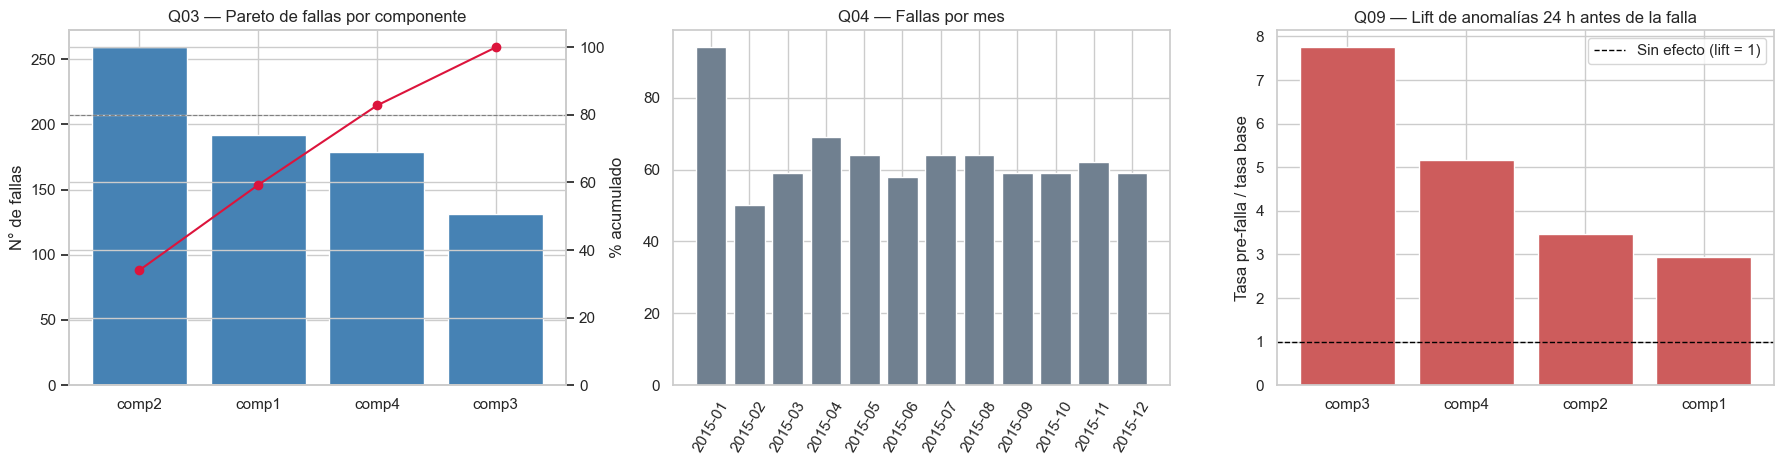

--- Q09: anomalías en las 24 h previas a falla vs tasa base ---


,componente,n_fallas,pct_anomalia_24h_previas,pct_anomalia_base,lift
2,comp3,131,36.87,4.76,7.75
3,comp4,179,24.54,4.76,5.16
1,comp2,259,16.52,4.76,3.47
0,comp1,192,14.01,4.76,2.94


--- Q10: vibración en las 24 h previas a falla vs promedio de flota ---


,componente,vib_prom_24h_previas,vib_prom_flota,delta_vibracion
3,comp4,50.40,40.39,10.01
1,comp2,40.81,40.39,0.42
0,comp1,40.52,40.39,0.13
2,comp3,40.42,40.39,0.03


In [22]:
# =========================================================================
# 9.3 RESULTADOS CLAVE: KPIs, PARETO, ANÁLISIS PRE-FALLA (100% PANDAS)
# =========================================================================

# --- 0. CÁLCULO EN MEMORIA DE Q09 Y Q10 (Análisis Pre-falla 24h) ---
if 'df_fact_events' in globals() and 'df_fact_tel' in globals():
    failures_only = df_fact_events[df_fact_events["event_type"] == "failure"].copy()
    
    # Base rate global de anomalías y vibración en telemetría
    base_rate = df_fact_tel["is_sensorial_anomaly"].mean()
    v_base = df_fact_tel["vibration"].mean()
    
    pre_anom_list = []
    pre_vib_list = []
    
    for idx, row in failures_only.iterrows():
        machine_id = row["machineID"]
        fail_time = row["datetime"]
        start_time = fail_time - pd.Timedelta(hours=24)
        comp = row["comp_or_failure"]
        
        # Ventana de 24 horas previas para la misma máquina
        mask = (df_fact_tel["machineID"] == machine_id) & (df_fact_tel["datetime"] > start_time) & (df_fact_tel["datetime"] <= fail_time)
        sub_tel = df_fact_tel[mask]
        
        if not sub_tel.empty:
            pre_anom_list.append({
                "fact_event_id": row.get("fact_event_id", idx),
                "componente": comp,
                "a": sub_tel["is_sensorial_anomaly"].mean()
            })
            pre_vib_list.append({
                "componente": comp,
                "v": sub_tel["vibration"].mean()
            })
            
    df_pre_anom = pd.DataFrame(pre_anom_list)
    df_pre_vib = pd.DataFrame(pre_vib_list)
    
    # Q09: Lift de anomalías 24h previas
    if not df_pre_anom.empty:
        q9 = df_pre_anom.groupby("componente").agg(
            n_fallas=("fact_event_id", "nunique"),
            pct_anomalia_24h_previas=("a", lambda x: round(100.0 * x.mean(), 2))
        ).reset_index()
        q9["pct_anomalia_base"] = round(100.0 * base_rate, 2)
        q9["lift"] = (q9["pct_anomalia_24h_previas"] / q9["pct_anomalia_base"]).round(2)
        results["Q09_anomalias_24h_previas_a_falla"] = q9.sort_values(by="lift", ascending=False)
    else:
        results["Q09_anomalias_24h_previas_a_falla"] = pd.DataFrame()
        
    # Q10: Vibración 24h previas
    if not df_pre_vib.empty:
        q10 = df_pre_vib.groupby("componente").agg(
            vib_prom_24h_previas=("v", lambda x: round(x.mean(), 2))
        ).reset_index()
        q10["vib_prom_flota"] = round(v_base, 2)
        q10["delta_vibracion"] = (q10["vib_prom_24h_previas"] - q10["vib_prom_flota"]).round(2)
        results["Q10_vibracion_24h_previas_a_falla"] = q10.sort_values(by="delta_vibracion", ascending=False)
    else:
        results["Q10_vibracion_24h_previas_a_falla"] = pd.DataFrame()

# --- 1. VISUALIZACIÓN Y DESPLIEGUE DE RESULTADOS ---
print("--- Q01: KPIs de confiabilidad por modelo ---")
display(results.get("Q01_kpi_por_modelo", pd.DataFrame()))

print("--- Q02: Top 10 máquinas con más fallas ---")
display(results.get("Q02_top10_maquinas_con_mas_fallas", pd.DataFrame()))

print("--- Q11: 3 peores máquinas por modelo (menor % uptime) ---")
display(results.get("Q11_3_peores_maquinas_por_modelo", pd.DataFrame()))

print("--- Q08: Mantenimientos por modelo y componente ---")
q8_res = results.get("Q08_mantenimientos_por_modelo_y_componente", pd.DataFrame())
if not q8_res.empty:
    display(q8_res.pivot(index="model", columns="componente", values="n_mantenimientos").fillna(0).astype(int))
else:
    display(q8_res)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Pareto de fallas por componente (barras + % acumulado)
pareto = results.get("Q03_pareto_fallas_por_componente", pd.DataFrame())
if not pareto.empty:
    axes[0].bar(pareto["componente"], pareto["n"], color="steelblue")
    ax2 = axes[0].twinx()
    ax2.plot(pareto["componente"], pareto["pct_acumulado"], color="crimson", marker="o")
    ax2.set_ylim(0, 105)
    ax2.set_ylabel("% acumulado")
    ax2.axhline(80, color="gray", linestyle="--", linewidth=0.8)
    axes[0].set_title("Q03 — Pareto de fallas por componente")
    axes[0].set_ylabel("N° de fallas")

# Fallas por mes
fm = results.get("Q04_fallas_por_mes", pd.DataFrame())
if not fm.empty:
    axes[1].bar(fm["year"].astype(str) + "-" + fm["month"].astype(str).str.zfill(2), fm["n_fallas"], color="slategray")
    axes[1].set_title("Q04 — Fallas por mes")
    axes[1].tick_params(axis="x", rotation=60)

# Lift de anomalías en las 24 h previas a la falla
lift = results.get("Q09_anomalias_24h_previas_a_falla", pd.DataFrame())
if not lift.empty:
    axes[2].bar(lift["componente"], lift["lift"], color="indianred")
    axes[2].axhline(1, color="black", linestyle="--", linewidth=1, label="Sin efecto (lift = 1)")
    axes[2].set_title("Q09 — Lift de anomalías 24 h antes de la falla")
    axes[2].set_ylabel("Tasa pre-falla / tasa base")
    axes[2].legend()

plt.tight_layout()
plt.show()

print("--- Q09: anomalías en las 24 h previas a falla vs tasa base ---")
display(lift)
print("--- Q10: vibración en las 24 h previas a falla vs promedio de flota ---")
display(results.get("Q10_vibracion_24h_previas_a_falla", pd.DataFrame()))

In [23]:
# =========================================================================
# VISUALIZACIÓN OPCIONAL DE Q05, Q06, Q07 Y Q12
# =========================================================================
print("--- Q05: Top 10 máquinas con más anomalías ---")
display(results.get("Q05_top10_maquinas_con_mas_anomalias", pd.DataFrame()))

print("--- Q06: Anomalías por modelo y sensor ---")
display(results.get("Q06_anomalias_por_modelo_y_sensor", pd.DataFrame()))

print("--- Q07: Errores por tipo ---")
display(results.get("Q07_errores_por_tipo", pd.DataFrame()))

print("--- Q12: Base Semáforo RAG (primeras 5 filas) ---")
q12_res = results.get("Q12_base_semaforo_rag", pd.DataFrame())
display(q12_res.head() if not q12_res.empty else q12_res)

--- Q05: Top 10 máquinas con más anomalías ---


,machineID,model,age,n_anomalias_iqr,pct_anomalia_iqr,pct_anomalia_zscore
20,21,model2,14,536,6.12,0.0
97,98,model2,20,502,5.73,0.0
84,85,model1,16,486,5.55,0.0
16,17,model1,14,483,5.51,0.0
66,67,model4,14,473,5.40,0.0
98,99,model1,14,471,5.38,0.0
68,69,model2,19,469,5.35,0.0
44,45,model3,14,465,5.31,0.0
12,13,model1,15,465,5.31,0.0
72,73,model2,20,463,5.28,0.0


--- Q06: Anomalías por modelo y sensor ---


,model,pct_consolidada
0,model1,5.13
1,model2,5.01
2,model3,4.66
3,model4,4.56


--- Q07: Errores por tipo ---


,error_id,n_errores,n_maquinas_afectadas,pct
0,error1,1010,100,25.77
1,error2,988,100,25.21
2,error3,838,100,21.38
3,error4,727,100,18.55
4,error5,356,93,9.08


--- Q12: Base Semáforo RAG (primeras 5 filas) ---


,machineID,model,age,n_failures,n_maint_events,MTBF_hours,MTTR_hours,pct_uptime,base_rate,vib_mu,vib_var,rate_24h,vib_24h,n_obs_24h
0,1,model3,18,7,37,1207.857143,6.954545,96.507248,0.048739,40.586309,30.715348,0.041667,39.762388,24
1,2,model4,7,4,32,2130.250000,6.666667,97.260587,0.047597,40.301539,28.228532,0.000000,40.218233,24
2,3,model3,8,5,37,1695.800000,6.714286,96.781189,0.052505,40.475376,27.551667,0.000000,37.615543,24
3,4,model3,7,6,33,1415.166667,6.923077,96.918160,0.047940,40.341620,28.083881,0.000000,39.381407,24
4,5,model3,2,7,35,1209.571429,7.000000,96.644219,0.049538,40.264846,28.050188,1.000000,39.033533,24


**Cómo leer el Bloque 9:**
- **Pareto (Q03):** los componentes que concentran ~80 % de las fallas procesadas en memoria son el foco del plan de mantenimiento preventivo.
- **Análisis de anomalías y eventos (Q05–Q08):** las métricas calculadas mediante agrupaciones y operaciones vectorizadas en Pandas permiten cuantificar el comportamiento por modelo, sensor y tipo de error.
- **Priorización y Semáforo RAG (Q11 y Q12):** consolidan el rendimiento operativo y el comportamiento reciente frente a la línea base para identificar de forma directa las máquinas en riesgo.

## BLOQUE 10: Semáforo RAG y Alertas Tempranas (Visualización)

**Lógica de Negocio:**
*RAG = Red / Amber / Green.* Se traduce el estado de salud de cada máquina en un semáforo accionable, combinando una dimensión **histórica** (disponibilidad) y dos señales **tempranas** de las últimas 24 h de telemetría calculadas directamente en memoria mediante Pandas (consulta Q12):

| Criterio | Tipo | Ámbar | Rojo |
|:---|:---|:---|:---|
| **% Uptime** | Histórico (KPI) | ≤ percentil 30 de la flota | ≤ percentil 10 de la flota |
| **Ratio de anomalías 24 h** | Temprana | $\geq 1.5\times$ la tasa base de la propia máquina | $\geq 3\times$ |
| **Z-score de vibración 24 h** | Temprana | $\geq 1.0\sigma$ sobre su media histórica | $\geq 2.0\sigma$ |

$$\text{RAG}_m = \max\big(\text{nivel}_{\text{uptime}},\ \text{nivel}_{\text{anomalías}},\ \text{nivel}_{\text{vibración}}\big)$$

El estado final es el **peor** de los tres criterios (principio de precaución). Las señales tempranas se comparan contra la línea base **de la propia máquina**, coherente con el criterio por máquina del Bloque 3. Todos los umbrales son parámetros configurables y deben calibrarse con el SLA real de planta antes de producción.

In [24]:
# =========================================================================
# 10.0 CÁLCULO DEL SEMÁFORO RAG (100% PANDAS Y NUMPY EN MEMORIA)
# =========================================================================
# Umbrales configurables del semáforo operativo
RAG_UPTIME_PCTL_RED    = 0.10   # uptime <= P10 de la flota → rojo
RAG_UPTIME_PCTL_AMBER = 0.30   # uptime <= P30 de la flota → ámbar
RAG_ANOM_RATIO_AMBER, RAG_ANOM_RATIO_RED = 1.5, 3.0
RAG_VIB_Z_AMBER, RAG_VIB_Z_RED = 1.0, 2.0

# Copia de trabajo desde los resultados en memoria generados en el Bloque 9
rag = results["Q12_base_semaforo_rag"].copy()
rag["rate_24h"] = rag["rate_24h"].fillna(0)
rag["vib_24h"]  = rag["vib_24h"].fillna(rag["vib_mu"])

# Señales tempranas relativas a la línea base de cada máquina
rag["anom_ratio"] = (rag["rate_24h"] / rag["base_rate"].replace(0, np.nan)).fillna(0)
rag["vib_z"] = (rag["vib_24h"] - rag["vib_mu"]) / np.sqrt(rag["vib_var"].clip(lower=1e-9))

# Nivel por criterio: 0 = verde, 1 = ámbar, 2 = rojo
p_red   = rag["pct_uptime"].quantile(RAG_UPTIME_PCTL_RED)
p_amber = rag["pct_uptime"].quantile(RAG_UPTIME_PCTL_AMBER)

lvl_uptime = np.select([rag["pct_uptime"] <= p_red, rag["pct_uptime"] <= p_amber], [2, 1], default=0)
lvl_anom   = np.select([rag["anom_ratio"] >= RAG_ANOM_RATIO_RED, rag["anom_ratio"] >= RAG_ANOM_RATIO_AMBER], [2, 1], default=0)
lvl_vib    = np.select([rag["vib_z"] >= RAG_VIB_Z_RED, rag["vib_z"] >= RAG_VIB_Z_AMBER], [2, 1], default=0)

rag["rag_level"] = np.maximum.reduce([lvl_uptime, lvl_anom, lvl_vib])
rag["rag_status"] = rag["rag_level"].map({0: "VERDE", 1: "ÁMBAR", 2: "ROJO"})

# Motivos legibles mediante concatenación vectorizada
def reason(level, red_txt, amber_txt):
    return pd.Series(np.where(level == 2, red_txt, np.where(level == 1, amber_txt, "")), index=rag.index)

rag["motivos"] = (
    reason(lvl_uptime, "Uptime crítico; ", "Uptime bajo; ")
    + reason(lvl_anom,  "Anomalías 24h muy sobre su base; ", "Anomalías 24h sobre su base; ")
    + reason(lvl_vib,   "Vibración 24h muy elevada; ", "Vibración 24h elevada; ")
).str.rstrip("; ")

# Puntaje de priorización dentro de cada nivel operativo
rag["risk_score"] = rag["anom_ratio"].clip(upper=10) + rag["vib_z"].clip(lower=0) + (100 - rag["pct_uptime"])

print(f"Umbrales de uptime de flota → P{int(RAG_UPTIME_PCTL_RED*100)} = {p_red:.2f}% | P{int(RAG_UPTIME_PCTL_AMBER*100)} = {p_amber:.2f}%")
print("\nDistribución del semáforo:")
print(rag["rag_status"].value_counts().reindex(["VERDE", "ÁMBAR", "ROJO"]).fillna(0).astype(int).to_string())

Umbrales de uptime de flota → P10 = 96.03% | P30 = 96.44%

Distribución del semáforo:
VERDE    44
ÁMBAR    31
ROJO     25


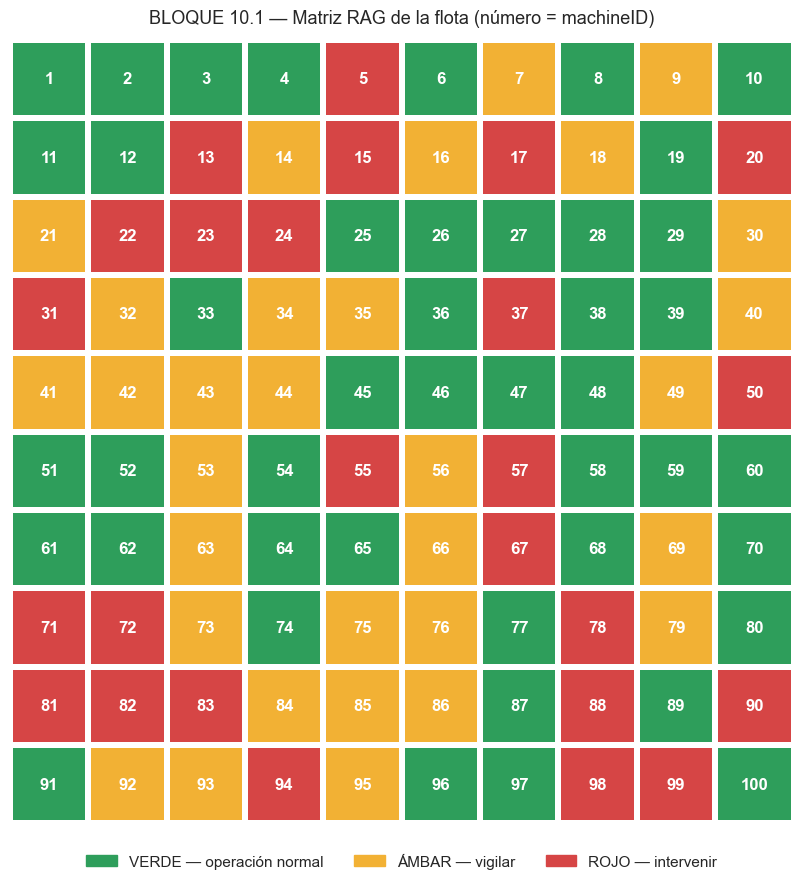

rag_status,VERDE,ÁMBAR,ROJO
model,,,
model1,1,7,8
model2,6,6,5
model3,20,11,4
model4,17,7,8


In [25]:
# =========================================================================
# 10.1 MATRIZ RAG 10 x 10 — UNA CELDA POR MÁQUINA (100% PANDAS)
# =========================================================================
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Ordenamiento y preparación de la matriz de visualización en memoria
rag_sorted = rag.sort_values("machineID").reset_index(drop=True)
n = len(rag_sorted)
ncols = 10
nrows = int(np.ceil(n / ncols))

levels_flat = np.full(nrows * ncols, np.nan)
levels_flat[:n] = rag_sorted["rag_level"].values
ids_flat = np.full(nrows * ncols, "", dtype=object)
ids_flat[:n] = rag_sorted["machineID"].astype(str).values

grid = levels_flat.reshape(nrows, ncols)
labels = ids_flat.reshape(nrows, ncols)

# Generación del gráfico de matriz con Seaborn y Matplotlib
fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    grid, 
    annot=labels, 
    fmt="", 
    cmap=ListedColormap(["#2e9e5b", "#f2b134", "#d64545"]),
    vmin=0, vmax=2, 
    cbar=False, 
    square=True, 
    linewidths=3, 
    linecolor="white",
    mask=np.isnan(grid), 
    annot_kws={"color": "white", "fontsize": 12, "fontweight": "bold"}, 
    ax=ax
)

ax.set_xticks([])
ax.set_yticks([])
ax.set_title("BLOQUE 10.1 — Matriz RAG de la flota (número = machineID)", fontsize=13, pad=12)

ax.legend(
    handles=[
        Patch(color="#2e9e5b", label="VERDE — operación normal"),
        Patch(color="#f2b134", label="ÁMBAR — vigilar"),
        Patch(color="#d64545", label="ROJO — intervenir")
    ],
    loc="upper center", 
    bbox_to_anchor=(0.5, -0.02), 
    ncol=3, 
    frameon=False
)

plt.tight_layout()
plt.show()

# Resumen cruzado por modelo de equipo usando Pandas Crosstab
display(
    pd.crosstab(rag["model"], rag["rag_status"])
      .reindex(columns=["VERDE", "ÁMBAR", "ROJO"], fill_value=0)
)

In [26]:
# =========================================================================
# 10.2 TARJETAS DE ALERTA TEMPRANA Y EXPORTACIÓN EN MEMORIA (100% PANDAS)
# =========================================================================
from IPython.display import HTML
import os

# Filtrado de alertas (niveles ÁMBAR o ROJO) ordenadas por prioridad de riesgo
alerts = (rag[rag["rag_level"] >= 1]
          .sort_values(["rag_level", "risk_score"], ascending=[False, False])
          .reset_index(drop=True))

COLORS = {"ROJO": "#d64545", "ÁMBAR": "#f2b134"}
TOP_N = 6

def card(r):
    color = COLORS[r.rag_status]
    return f"""
    <div style="border-left:8px solid {color}; background:#ffffff; color:#1f2933; border-radius:6px;
                padding:12px 16px; margin:8px; width:300px; box-shadow:0 1px 4px rgba(0,0,0,.25);
                font-family:Arial,sans-serif;">
      <div style="font-size:12px; font-weight:bold; color:{color};">{r.rag_status}</div>
      <div style="font-size:18px; font-weight:bold;">Máquina {int(r.machineID)} · {r.model}</div>
      <div style="font-size:12px; color:#52606d;">Antigüedad: {int(r.age)} años · Fallas históricas: {int(r.n_failures)}</div>
      <hr style="border:none; border-top:1px solid #e4e7eb; margin:8px 0;">
      <div style="font-size:13px;">Uptime: <b>{r.pct_uptime:.2f}%</b></div>
      <div style="font-size:13px;">Anomalías 24h: <b>{r.rate_24h*100:.1f}%</b> ({r.anom_ratio:.1f}× su base)</div>
      <div style="font-size:13px;">Vibración 24h: <b>{r.vib_24h:.1f} Hz</b> ({r.vib_z:+.1f}σ)</div>
      <div style="font-size:12px; margin-top:6px; color:#3e4c59;"><i>{r.motivos}</i></div>
    </div>"""

if alerts.empty:
    print("Sin alertas activas: toda la flota está en VERDE.")
else:
    cards_html = "".join(card(r) for r in alerts.head(TOP_N).itertuples())
    display(HTML(f"<div style='display:flex; flex-wrap:wrap;'>{cards_html}</div>"))
    print(f"Se muestran las {min(TOP_N, len(alerts))} alertas de mayor prioridad de {len(alerts)} activas.")

# --- Exportación del tablero de alertas completo directamente desde Pandas ---
alert_cols = ["machineID", "model", "age", "n_failures", "pct_uptime", "rate_24h", "anom_ratio",
              "vib_24h", "vib_z", "rag_status", "motivos", "risk_score"]

os.makedirs(OUTPUT_DIR, exist_ok=True)
output_file_path = os.path.join(OUTPUT_DIR, "Alertas_Tempranas_RAG.csv")

rag.sort_values(["rag_level", "risk_score"], ascending=[False, False])[alert_cols] \
   .to_csv(output_file_path, index=False)

print(f"\nTablero de alertas exportado exitosamente en: {output_file_path}")
print("Flujo analítico 100% en memoria completado sin dependencias SQL.")

Se muestran las 6 alertas de mayor prioridad de 56 activas.

Tablero de alertas exportado exitosamente en: data_processed\Alertas_Tempranas_RAG.csv
Flujo analítico 100% en memoria completado sin dependencias SQL.


### Cierre de los Bloques 8–10

Artefacto nuevo generado en `./data_processed/`:

| Archivo | Contenido |
|:---|:---|
| `Alertas_Tempranas_RAG.csv` | Semáforo operativo RAG, motivos y puntaje de riesgo por máquina para consumo directo |

Con esto el notebook cubre el flujo completo en memoria: **ETL vectorizado → modelado analítico en memoria → KPIs industriales → EDA de series temporales → lógica de negocio y semáforo de alertas tempranas con Pandas y NumPy**.

### Notas Finales de Auditoría & Consideraciones de Dominio

* **Soberanía y Conservación Incondicional del Dato:**  
  Ningún valor de la telemetría continua (`volt`, `rotate`, `pressure`, `vibration`) fue imputado por media/mediana ni eliminado por ser extremo. Los picos operativos permanecen intactos en su valor físico original y quedan categorizados en las flags dinámicas `is_*_anomaly` e `is_sensorial_anomaly`.

* **Tratamiento de Nulos Lógicos en Ingeniería de Confiabilidad:**  
  Las máquinas pertenecientes al grupo de control (sin registros de eventos en `PdM_failures`) conservan `n_failures = 0`. En lugar de imputar un valor sintético o dejar valores nulos indeterminados en el cálculo del $MTBF$, se les asigna el total del horizonte temporal observado ($T_{\text{observado}}$), reflejando una disponibilidad operativa del 100% libre de fallas catastróficas.

* **Preservación de Eventos Simultáneos Legítimos:**  
  Los registros concurrentes en la misma marca de tiempo (`timestamp`) dentro de `PdM_errors`, `PdM_maint` y `PdM_failures` se preservan íntegramente como filas independientes en la tabla de hechos `Fact_SystemFailures`, identificados inequívocamente mediante la clave subrogada `failure_sk`.

* **Calibración de Supuestos Operativos (SLA de Planta):**  
  Las constantes de tiempo fuera de servicio (`MAINT_DOWNTIME_HOURS = 6.0` hrs y `FAILURE_DOWNTIME_HOURS = 12.0` hrs) actúan como parámetros configurables para el cálculo de $MTTR$ y $\%$ $Uptime$. Previo al despliegue en un entorno de producción, estos parámetros deben validarse y sincronizarse directamente contra los registros reales de duraciones del sistema CMMS/SAP PM.